# Segmentation des utilisateurs d'Instagram : usage et bien-être

**Rush 4 · Bootcamp Data · Epitech**

*Livrable final de l'équipe : analyse, segmentation et recommandations.*

## Objectif
**Étudier les relations entre l'utilisation d'Instagram et le bien-être des utilisateurs**, à partir d'un jeu de données de 200 000 personnes.

Le département Innovation d'Instagram nous demande de **livrer une segmentation des utilisateurs** qui :
- **repose sur leur usage** de l'application ;
- **explique le lien entre l'usage et le bien-être** ;
- est **utilisable par les équipes produit** ;
- est **défendue devant un jury**.

## Le contexte
Les réseaux sociaux doivent prouver qu'ils ne nuisent pas à leurs utilisateurs : les régulateurs posent des questions, la presse publie des études et les annonceurs ne veulent pas être associés à une plateforme qui rend les gens malheureux. Instagram veut **sa propre réponse, fondée sur ses propres données**.

- Les données de **bien-être et de santé** (stress, bonheur, sommeil…) viennent d'un **panel de volontaires** qui ont accepté une étude bien-être.
- Les données d'**usage** (temps passé, sessions, likes…) et de **profil** (âge, pays…) existent pour **tous** les utilisateurs.
- Nous travaillons sur une **réplique synthétique** du panel, fournie par l'équipe vie privée. Nos recommandations, elles, s'appliqueront à de vrais utilisateurs.

## Définitions
- **Bien-être :** l'Organisation mondiale de la santé définit la santé comme « un état de complet bien-être physique, mental et social », qui ne se réduit pas à l'absence de maladie ([constitution de l'OMS](https://www.who.int/fr/about/governance/constitution)). La santé mentale y est décrite comme un état de bien-être qui permet notamment de surmonter les tensions normales de la vie ([Santé publique France, sante.fr](https://www.sante.fr/toutes-et-tous-une-sante-mentale)). Nous mesurons le bien-être avec **deux indicateurs** : le stress et le bonheur.
- **Bonheur :** une **auto-évaluation** de sa propre vie sur une échelle, comme l'échelle de Cantril (de 0 à 10) utilisée par le [World Happiness Report](https://www.worldhappiness.report/faq/). Dans nos données, le **bonheur déclaré** (`self_reported_happiness`) va de 1 à 10.
- **Stress :** le **stress perçu** (`perceived_stress_score`) va de 0 à 40. C'est la plage de l'échelle **PSS-10**, sans que la documentation le confirme. On considère le stress comme **élevé à partir de 27**, une convention de lecture courante et non un seuil de diagnostic ([guide de cotation, NovoPsych](https://novopsych.com.au/wp-content/uploads/2022/02/pss-10-report-PDF.pdf)).
- **Plus heureux / moins heureux** (aussi appelés très heureux / très malheureux) **:** les utilisateurs au bonheur de **9 ou 10** (20 % des utilisateurs) et de **1 ou 2** (20 % des utilisateurs).

## Les règles suivies
- **Aucune donnée individuelle n'est affichée** : seulement des moyennes de groupes, et jamais un groupe de **moins de 100 utilisateurs**.
- **Résultats identiques à chaque exécution** : aucun tirage aléatoire.
- **« À temps égal »** : on compare des utilisateurs qui passent le même temps sur Instagram (par tranches de 10 minutes). C'est ce qui permet de savoir si une habitude compte **en plus** du temps passé.
- **Ce sont des corrélations**, pas des preuves de cause à effet.

## Le plan
0. Nettoyage et données
1. Les hypothèses non concluantes
2. Le temps passé sur Instagram
3. Le rôle de l'âge
4. Les habitudes d'utilisation
5. Stress et bonheur
6. La segmentation
7. Protection des données
8. Limites
9. Conclusion et recommandations

En annexe : les sources.

L'application Streamlit `notebook_Instagram_final.py` présente exactement les mêmes résultats, sous forme interactive.

---
## Préparation : bibliothèques, outils et données

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Couleurs (palette vérifiée pour les daltonismes les plus courants)
SURFACE = "#fcfcfb"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLEU, ORANGE, AQUA, ROUGE = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
BLEU_CLAIR, ROUGE_CLAIR = "#95bbea", "#f1a4a4"
RAMPE_4 = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "bleu", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (9, 4.6),
    "font.family": "sans-serif", "font.size": 10.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})


def fr(valeur, decimales=1):
    """Écrit un nombre à la française : virgule décimale, espace pour les milliers."""
    if pd.isna(valeur):
        return "—"
    if round(valeur, decimales) == 0:
        valeur = 0.0
    return f"{valeur:,.{decimales}f}".replace(",", " ").replace(".", ",")


def afficher(table, decimales=1):
    """Affiche un tableau agrégé avec des nombres au format français."""
    def formater(v):
        if isinstance(v, (bool, np.bool_)):
            return "oui" if v else "non"
        if isinstance(v, (int, np.integer)):
            return fr(v, 0)
        if isinstance(v, (float, np.floating)):
            return fr(v, decimales)
        return v
    display(table.apply(lambda colonne: colonne.map(formater)))


def titrer(ax, titre, sous_titre=None):
    ax.set_title(titre, loc="left", pad=26 if sous_titre else 10)
    if sous_titre:
        ax.text(0, 1.02, sous_titre, transform=ax.transAxes, fontsize=9.5, color=INK2, ha="left", va="bottom")


def titrer_figure(fig, titre, sous_titre=None):
    """Titre d'une figure à plusieurs panneaux (à appeler après tight_layout)."""
    if sous_titre:
        fig.text(0.01, 1.0, sous_titre, ha="left", va="bottom", fontsize=9.5, color=INK2)
    fig.text(0.01, 1.0 + (0.28 / fig.get_figheight() if sous_titre else 0), titre, ha="left", va="bottom",
             fontsize=12.5, fontweight="semibold", color=INK)


def panneau(ax, titre):
    ax.set_title(titre, fontsize=10.5, loc="left", pad=8)


def barres(ax, valeurs, etiquettes, couleur=BLEU, decimales=1, suffixe="", rotation=0):
    """Barres verticales avec la valeur écrite au-dessus de chaque barre."""
    valeurs = np.asarray(valeurs, dtype=float)
    positions = np.arange(len(valeurs))
    ax.bar(positions, valeurs, width=0.55, color=couleur)
    for p, v in zip(positions, valeurs):
        ax.text(p, v + np.nanmax(valeurs) * 0.015, fr(v, decimales) + suffixe, ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(positions, etiquettes, rotation=rotation, ha="right" if rotation else "center")
    ax.grid(axis="x", visible=False)


def barres_groupees(ax, table, couleurs, decimales=1, rotation=0, suffixe=""):
    """Barres groupées : une ligne par groupe, une couleur par colonne du tableau."""
    n = table.shape[1]
    largeur = 0.8 / n
    x = np.arange(len(table))
    for k, (colonne, couleur) in enumerate(zip(table.columns, couleurs)):
        positions = x - 0.4 + largeur * (k + 0.5)
        ax.bar(positions, table[colonne], width=largeur * 0.9, color=couleur, label=colonne)
        for p, v in zip(positions, table[colonne]):
            ax.text(p, v + table.to_numpy().max() * 0.012, fr(v, decimales) + suffixe, ha="center", va="bottom", fontsize=7.8, color=INK2)
    ax.set_xticks(x, table.index, rotation=rotation, ha="right" if rotation else "center")
    ax.grid(axis="x", visible=False)


def carte_chaleur(ax, grille, vmin, vmax, etiquette, decimales=0, suffixe="", seuil=0.55):
    valeurs = grille.to_numpy(dtype=float)
    palette = CMAP_SEQ.copy()
    palette.set_bad(SURFACE)
    image = ax.imshow(np.ma.masked_invalid(valeurs), cmap=palette, vmin=vmin, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(valeurs):
        if not np.isnan(v):
            ax.text(j, i, fr(v, decimales) + suffixe, ha="center", va="center", fontsize=9,
                    color=INK if (v - vmin) / (vmax - vmin) < seuil else "white")
    ax.set_xticks(range(grille.shape[1]), grille.columns)
    ax.set_yticks(range(grille.shape[0]), grille.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for cote in ax.spines.values():
        cote.set_visible(False)
    barre = plt.colorbar(image, ax=ax, shrink=0.85, pad=0.02)
    barre.set_label(etiquette, color=INK2)
    barre.outline.set_visible(False)


FORMAT_HEURES = FuncFormatter(lambda v, _: f"{int(v)} h" if float(v).is_integer() else "")
FORMAT_POURCENT = FuncFormatter(lambda v, _: f"{v:.0f} %")

In [2]:
CANDIDATS = [Path("data/instagram_usage_lifestyleSafe.csv"), Path("../data/instagram_usage_lifestyleSafe.csv")]
CHEMIN = next((p for p in CANDIDATS if p.exists()), None)
assert CHEMIN is not None, "Fichier introuvable : placez les deux CSV dans un dossier data/ à côté du notebook."
CHEMIN_AUTRE = CHEMIN.with_name("instagram_users_lifestyleSafe.csv")
df = pd.read_csv(CHEMIN)

STRESS = "perceived_stress_score"
BONHEUR = "self_reported_happiness"
TEMPS = "daily_active_minutes_instagram"
MIN_N = 100  # taille minimale d'un groupe affiché

SEGMENTS = ["S1 Très occasionnel", "S2 Occasionnel", "S3 Modéré", "S4 Soutenu", "S5 Intensif", "S6 Très intensif"]
BORNES_SEGMENTS = [0, 20, 88, 188, 240, 290, np.inf]
DUREES_SEGMENTS = ["< 20 min", "20–88 min", "88–188 min", "188–240 min", "240–290 min", "> 290 min"]
COURTS = ["S1", "S2", "S3", "S4", "S5", "S6"]
TRANCHES_AGE = ["13–17 ans", "18–24 ans", "25–34 ans", "35–44 ans", "45–54 ans", "55–65 ans"]
GROUPES_AGE = ["13–17 ans", "18–34 ans", "35–54 ans", "55–65 ans"]
BORNES_GROUPES_AGE = [13, 18, 35, 55, 66]


def agreger(data, cles, **mesures):
    """Moyennes par groupe ; les groupes de moins de MIN_N utilisateurs sont retirés."""
    table = data.groupby(cles, observed=True).agg(n=(STRESS, "size"), **mesures)
    return table[table["n"] >= MIN_N]


def part_expliquee(data, y, cles):
    """Part des écarts de y entre utilisateurs expliquée par les groupes (de 0 à 1)."""
    moyenne_groupe = data.groupby(cles, observed=True)[y].transform("mean")
    return 1 - ((data[y] - moyenne_groupe) ** 2).sum() / ((data[y] - data[y].mean()) ** 2).sum()


def correlation_rangs(a, b):
    """Corrélation de Spearman (de −1 à 1), calculée sur les rangs : même résultat, sans dépendre de scipy."""
    return float(a.rank().corr(b.rank()))


def a_temps_egal(data, colonne, groupes="tranche_10min"):
    """Valeur ramenée à temps passé égal : écart à la moyenne de la même tranche, plus la moyenne générale."""
    return data[colonne] - data.groupby(groupes)[colonne].transform("mean") + data[colonne].mean()

---
## 0. Nettoyage et données
*Vérifier la qualité des données, choisir le bon fichier et construire les variables utiles.*

### 0.1 Contrôles de base et variables inutiles

In [3]:
controles = pd.Series({
    "utilisateurs": len(df),
    "colonnes": df.shape[1],
    "valeurs manquantes": int(df.isna().sum().sum()),
    "lignes en double (hors identifiant)": int(df.drop(columns="user_id").duplicated().sum()),
    "identifiants en double": int(df["user_id"].duplicated().sum()),
}, name="valeur").to_frame()
afficher(controles)

,valeur
utilisateurs,200 000
colonnes,58
valeurs manquantes,0
lignes en double (hors identifiant),0
identifiants en double,0


In [4]:
inutiles = pd.DataFrame({"constat": [
    f"une seule valeur : « {df['app_name'].iloc[0]} »",
    f"variation de {fr(df['daily_steps_count'].std() / df['daily_steps_count'].mean() * 100, 1)} % autour de la moyenne",
    f"égale aux minutes ÷ sessions (écart maximal : {fr((df[TEMPS] / df['sessions_per_day'] - df['average_session_length_minutes']).abs().max(), 2)} min)",
]}, index=["app_name", "daily_steps_count", "average_session_length_minutes"]).rename_axis("colonne")
display(inutiles)

,constat
colonne,
app_name,une seule valeur : « Instagram »
daily_steps_count,"variation de 1,1 % autour de la moyenne"
average_session_length_minutes,égale aux minutes ÷ sessions (écart maximal : ...


### 0.2 Incohérences métier : signalées, pas supprimées

Quatre règles repèrent des valeurs impossibles. Chaque ligne concernée reçoit un indicateur `flag_*`, sans être supprimée.

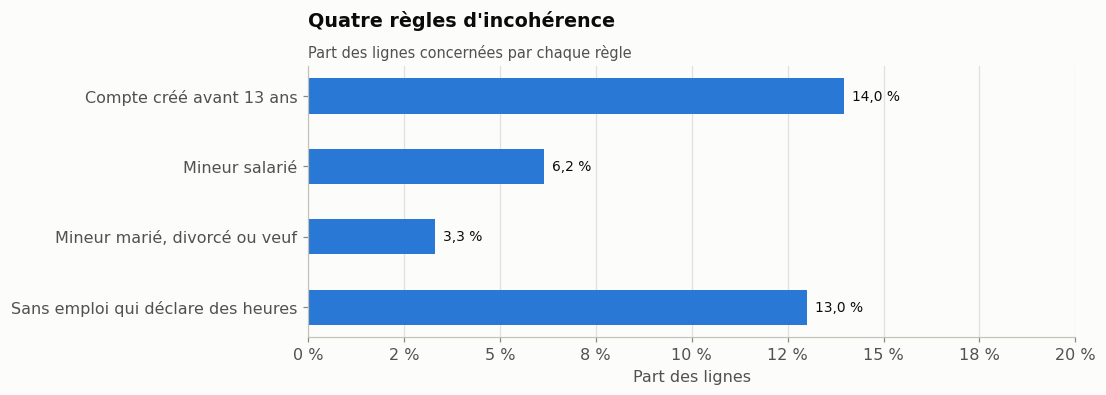

Lignes avec au moins une incohérence : 26 %
Part du stress expliquée par le temps passé : 70,7 % avec toutes les lignes, 71,4 % sans les lignes signalées


In [5]:
age_creation = df["age"] - (2025 - df["account_creation_year"])
drapeaux = pd.DataFrame({
    "flag_compte_avant_13_ans": age_creation < 13,
    "flag_mineur_salarie": (df["age"] < 18) & df["employment_status"].isin(["Full-time employed", "Part-time", "Freelancer"]),
    "flag_mineur_marie": (df["age"] < 18) & df["relationship_status"].isin(["Married", "Divorced", "Widowed"]),
    "flag_sans_emploi_avec_heures": df["employment_status"].isin(["Unemployed", "Retired"]) & (df["weekly_work_hours"] > 0),
})
REGLES = {"flag_compte_avant_13_ans": "Compte créé avant 13 ans",
          "flag_mineur_salarie": "Mineur salarié",
          "flag_mineur_marie": "Mineur marié, divorcé ou veuf",
          "flag_sans_emploi_avec_heures": "Sans emploi qui déclare des heures"}
parts_drapeaux = drapeaux.mean().mul(100).rename(REGLES)
signalees = drapeaux.any(axis=1)

propre = df[~signalees]
r2_propre = part_expliquee(propre, STRESS, propre[TEMPS] // 10)
r2_tout = part_expliquee(df, STRESS, df[TEMPS] // 10)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(range(len(parts_drapeaux)), parts_drapeaux, height=0.5, color=BLEU)
for p, v in enumerate(parts_drapeaux):
    ax.text(v + 0.2, p, f"{fr(v)} %", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(parts_drapeaux)), parts_drapeaux.index)
ax.invert_yaxis()
ax.set_xlim(0, 20)
ax.xaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Part des lignes")
titrer(ax, "Quatre règles d'incohérence", "Part des lignes concernées par chaque règle")
plt.show()

print(f"Lignes avec au moins une incohérence : {fr(signalees.mean() * 100, 0)} %")
print(f"Part du stress expliquée par le temps passé : {fr(r2_tout * 100, 1)} % avec toutes les lignes, "
      f"{fr(r2_propre * 100, 1)} % sans les lignes signalées")

- **26 %** des lignes ont au moins une incohérence : comptes créés avant 13 ans, mineurs salariés ou mariés, sans-emploi (chômeurs ou retraités) qui déclarent des heures de travail.
- Ces incohérences touchent l'emploi, la situation de couple, les heures de travail et l'année de création du compte : **aucune de ces colonnes ne sert à la segmentation**.
- Sans les lignes signalées, le temps passé explique toujours **71 %** des écarts de stress : **les résultats ne dépendent pas de ces lignes**.

### 0.3 Quel fichier croire, et sur quels champs ?

Instagram nous a envoyé **deux versions presque identiques** de la réplique (« usage » et « users »). L'une a subi un nettoyage non documenté. La consigne nous demande de décider laquelle croire, champ par champ.

In [6]:
if CHEMIN_AUTRE.exists():
    autre = pd.read_csv(CHEMIN_AUTRE)
    differences = pd.Series({c: int((df[c].astype(str) != autre[c].astype(str)).sum()) for c in autre.columns})
    print(f"Mêmes utilisateurs dans le même ordre : {df['user_id'].equals(autre['user_id'])}")
    print(f"Colonnes identiques : {int((differences == 0).sum())} sur {len(differences)}")
    afficher(differences[differences > 0].rename("lignes différentes").to_frame().rename_axis("colonne"), 0)
    mineurs = df["age"] < 18
    afficher(pd.DataFrame({
        "fichier usage (analysé)": {
            "part déclarée salariée à temps plein (%)": (df.loc[mineurs, "employment_status"] == "Full-time employed").mean() * 100,
            "heures de travail par semaine (moyenne)": df.loc[mineurs, "weekly_work_hours"].mean()},
        "fichier users (autre version)": {
            "part déclarée salariée à temps plein (%)": (autre.loc[mineurs, "employment_status"] == "Full-time employed").mean() * 100,
            "heures de travail par semaine (moyenne)": autre.loc[mineurs, "weekly_work_hours"].mean()}}))
    COLONNES_UTILISEES = [STRESS, BONHEUR, TEMPS, "age", "sleep_hours_per_night", "daily_steps_count", "exercise_hours_per_week",
                          "sessions_per_day", "average_session_length_minutes", "likes_given_per_day", "comments_written_per_day",
                          "posts_created_per_week", "dms_sent_per_week", "privacy_setting_level", "country"]
    identiques = all(df[c].astype(str).equals(autre[c].astype(str)) for c in COLONNES_UTILISEES)
    print(f"Les colonnes utilisées dans l'analyse sont identiques dans les deux fichiers : {identiques}")
    del autre
else:
    print("Fichier instagram_users_lifestyleSafe.csv absent : la comparaison n'est pas recalculée.")

Mêmes utilisateurs dans le même ordre : True
Colonnes identiques : 52 sur 58


,lignes différentes
colonne,
employment_status,18 913
education_level,1 203
relationship_status,6 623
has_children,5 329
weekly_work_hours,18 912
account_creation_year,31 772


,fichier usage (analysé),fichier users (autre version)
part déclarée salariée à temps plein (%),"45,4","0,0"
heures de travail par semaine (moyenne),"40,0","0,0"


Les colonnes utilisées dans l'analyse sont identiques dans les deux fichiers : True


**Notre décision**
- Les deux fichiers ont les mêmes utilisateurs et **52 colonnes sur 58 identiques**. Dans le fichier `usage`, 45 % des 13–17 ans sont déclarés salariés à temps plein : le fichier `users` a corrigé cette incohérence.
- **Toutes les colonnes que nous utilisons** sont **identiques dans les deux fichiers** : nos résultats ne dépendent pas de ce choix. Nous travaillons sur le fichier `usage`.
- **Pour l'emploi et les heures de travail**, nous faisons confiance au fichier `users`. Nous n'utilisons pas ces colonnes.

### 0.4 Les variables construites
- **Six segments de temps passé** (S1 à S6), dont les seuils séparent les niveaux de stress et de bonheur : moins de 20 min, 20–88 min, 88–188 min, 188–240 min, 240–290 min, plus de 290 min.
- **Quatre groupes d'âge** (13–17, 18–34, 35–54, 55–65 ans) : les mineurs à part, pour des raisons légales.
- **Un indicateur « stress élevé »** (27 ou plus sur 40).

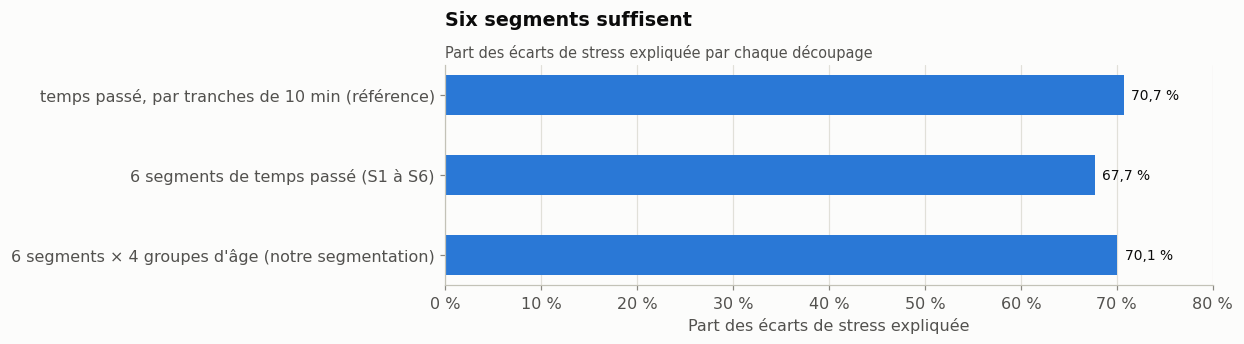

In [7]:
df["heures"] = df[TEMPS] / 60
df["tranche_10min"] = (df[TEMPS] // 10).astype(int)
df["tranche_30min"] = ((df[TEMPS] // 30) * 30).astype(int)
df["segment"] = pd.cut(df[TEMPS], BORNES_SEGMENTS, right=False, labels=SEGMENTS)
df["tranche_age"] = pd.cut(df["age"], [13, 18, 25, 35, 45, 55, 66], right=False, labels=TRANCHES_AGE)
df["groupe_age"] = pd.cut(df["age"], BORNES_GROUPES_AGE, right=False, labels=GROUPES_AGE)
df["stress_eleve"] = df[STRESS] >= 27
df["tres_heureux"] = df[BONHEUR] >= 9
df["tres_malheureux"] = df[BONHEUR] <= 2
df["tranche_10min_age"] = df["tranche_10min"].astype(str) + "_" + df["age"].astype(str)
df["stress_temps_egal"] = a_temps_egal(df, STRESS)
df["bonheur_temps_egal"] = a_temps_egal(df, BONHEUR)

apport = pd.Series({
    "temps passé, par tranches de 10 min (référence)": part_expliquee(df, STRESS, ["tranche_10min"]) * 100,
    "6 segments de temps passé (S1 à S6)": part_expliquee(df, STRESS, ["segment"]) * 100,
    "6 segments × 4 groupes d'âge (notre segmentation)": part_expliquee(df, STRESS, ["segment", "groupe_age"]) * 100,
})
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(range(len(apport)), apport, height=0.5, color=BLEU)
for p, v in enumerate(apport):
    ax.text(v + 0.8, p, f"{fr(v)} %", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(apport)), apport.index)
ax.invert_yaxis()
ax.set_xlim(0, 80)
ax.xaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Part des écarts de stress expliquée")
titrer(ax, "Six segments suffisent", "Part des écarts de stress expliquée par chaque découpage")
plt.show()

> **Ce qu'on retient :** le fichier est complet et sans doublon ; les incohérences sont signalées sans changer les résultats ; les six segments de temps conservent presque toute l'information du temps passé (68 % des écarts de stress expliqués, contre 71 % avec le temps à 10 minutes près).

---
## 1. Les hypothèses non concluantes
*Le sommeil, l'activité physique et le pays : trois pistes qui ne se vérifient pas dans notre panel, alors que les deux premières sont appuyées par des sources de santé publique.*

Un indicateur sans lien avec l'usage est aussi un résultat. La durée des sessions est traitée avec la fréquence de connexion (partie 4.4).

### 1.1 Le sommeil
**Questions :** Instagram fait-il baisser le nombre d'heures de sommeil ? Le manque de sommeil joue-t-il un rôle dans le bien-être ?

**Source :** [info.gouv.fr, « Santé mentale : pourquoi le sommeil joue un rôle clé », 2025](https://www.info.gouv.fr/actualite/sante-mentale-pourquoi-le-sommeil-joue-un-role-cle) — « Avoir une bonne santé du sommeil contribue à avoir une bonne santé mentale. »

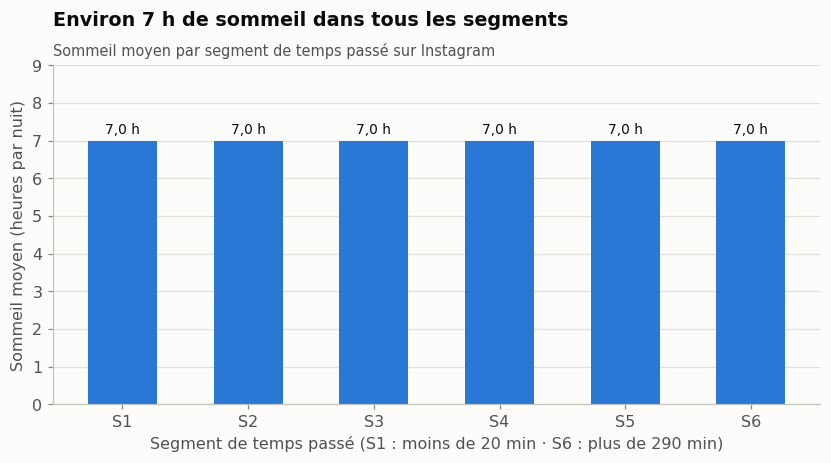

,n,sommeil_moyen,part_moins_de_6h
segment,,,
S1 Très occasionnel,14 512,"7,00","17,12"
S2 Occasionnel,27 884,"7,00","17,43"
S3 Modéré,57 823,"7,00","17,16"
S4 Soutenu,31 384,"7,00","16,83"
S5 Intensif,27 617,"6,99","17,42"
S6 Très intensif,40 780,"7,00","17,09"


In [8]:
sommeil = agreger(df, "segment", sommeil_moyen=("sleep_hours_per_night", "mean"),
                  part_moins_de_6h=("sleep_hours_per_night", lambda s: (s < 6).mean() * 100))
fig, ax = plt.subplots(figsize=(9, 4))
barres(ax, sommeil["sommeil_moyen"], COURTS, suffixe=" h")
ax.set_ylim(0, 9)
ax.set_xlabel("Segment de temps passé (S1 : moins de 20 min · S6 : plus de 290 min)")
ax.set_ylabel("Sommeil moyen (heures par nuit)")
titrer(ax, "Environ 7 h de sommeil dans tous les segments", "Sommeil moyen par segment de temps passé sur Instagram")
plt.show()
afficher(sommeil.rename_axis("segment"), 2)

Le sommeil moyen est d'environ **7 h** et la part de petits dormeurs (moins de 6 h) d'environ **17 %**, dans tous les segments.

### 1.2 L'activité physique : pas et sport
**Questions :** le temps passé sur Instagram fait-il baisser l'activité physique ? L'activité physique joue-t-elle un rôle sur le bien-être ?

**Source :** [Ameli, « Sport et activité physique : un atout pour le bien-être »](https://www.ameli.fr/assure/sante/themes/activite-physique-sante/sport-et-activite-physique-un-atout-pour-le-bien-etre) — l'activité physique réduit le stress et l'anxiété, régule l'humeur et améliore le sommeil.

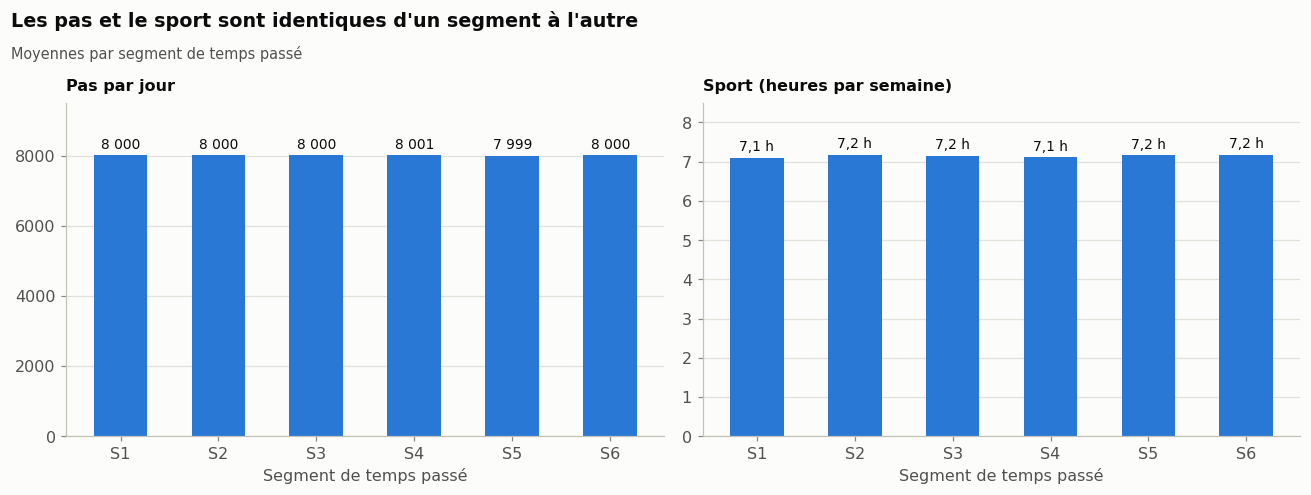

,lien avec le temps passé,lien avec le stress,lien avec le bonheur
Sommeil,"-0,001","0,000","0,003"
Pas par jour,"-0,002","-0,002","-0,005"
Sport,"0,001","-0,002","-0,007"


In [9]:
activite = agreger(df, "segment", pas_par_jour=("daily_steps_count", "mean"), sport_heures_semaine=("exercise_hours_per_week", "mean"))
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4))
barres(ax_g, activite["pas_par_jour"], COURTS, decimales=0)
ax_g.set_ylim(0, 9500)
panneau(ax_g, "Pas par jour")
barres(ax_d, activite["sport_heures_semaine"], COURTS, suffixe=" h")
ax_d.set_ylim(0, 8.5)
panneau(ax_d, "Sport (heures par semaine)")
for ax in (ax_g, ax_d):
    ax.set_xlabel("Segment de temps passé")
fig.tight_layout()
titrer_figure(fig, "Les pas et le sport sont identiques d'un segment à l'autre", "Moyennes par segment de temps passé")
plt.show()

NOMS_VIE = (("sleep_hours_per_night", "Sommeil"), ("daily_steps_count", "Pas par jour"), ("exercise_hours_per_week", "Sport"))
afficher(pd.DataFrame({
    "lien avec le temps passé": {n: correlation_rangs(df[c], df[TEMPS]) for c, n in NOMS_VIE},
    "lien avec le stress": {n: correlation_rangs(df[c], df[STRESS]) for c, n in NOMS_VIE},
    "lien avec le bonheur": {n: correlation_rangs(df[c], df[BONHEUR]) for c, n in NOMS_VIE},
}), 3)

Environ **8 000 pas par jour** et **7,1 à 7,2 h de sport par semaine** dans tous les segments. Le nombre de pas varie à peine (98 % des utilisateurs entre 7 794 et 8 208) : cette variable ne permet pas de distinguer des profils. Ni le sommeil, ni les pas, ni le sport ne sont liés au temps passé, au stress ou au bonheur (corrélations proches de 0).

### 1.3 Le pays
**Question :** le pays change-t-il le bien-être ?

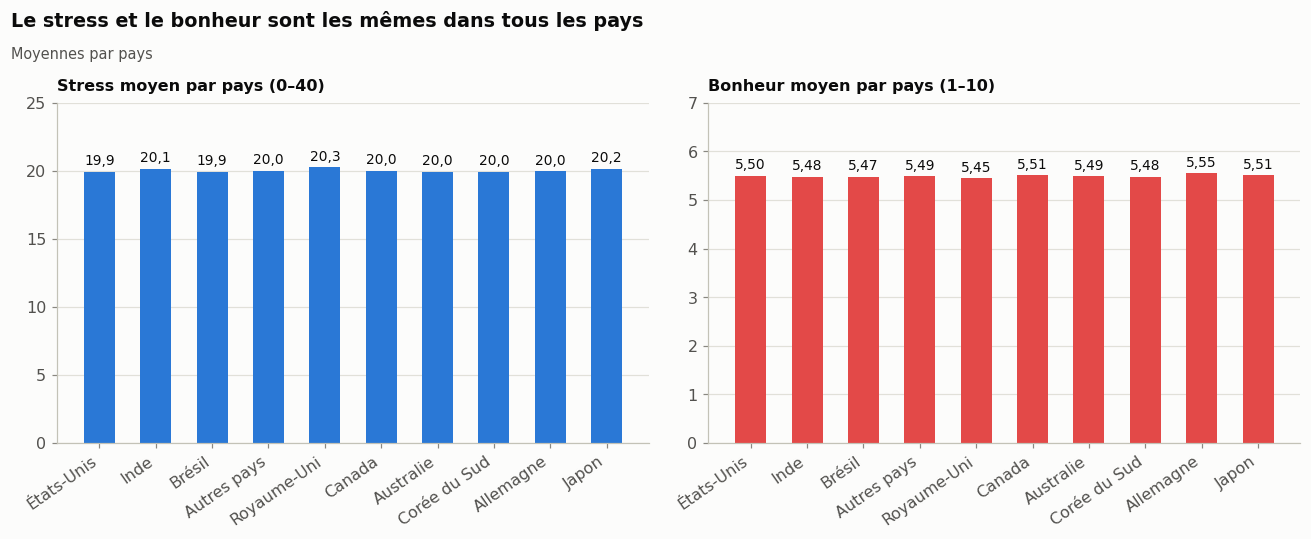

,n,minutes,stress,bonheur,stress_temps_egal,bonheur_temps_egal
pays,,,,,,
États-Unis,49 964,"187,67","19,94","5,50","20,04","5,49"
Inde,36 094,"189,95","20,14","5,48","20,02","5,48"
Brésil,23 865,"188,19","19,91","5,47","19,96","5,47"
Autres pays,20 157,"188,33","20,03","5,49","20,07","5,49"
Royaume-Uni,15 828,"191,36","20,26","5,45","20,02","5,47"
Canada,13 954,"188,36","20,00","5,51","20,04","5,51"
Australie,12 065,"188,67","19,95","5,49","19,95","5,49"
Corée du Sud,10 048,"188,74","19,95","5,48","19,93","5,47"
Allemagne,9 994,"187,19","19,96","5,55","20,09","5,53"


In [10]:
PAYS = {"United States": "États-Unis", "India": "Inde", "Brazil": "Brésil", "Other": "Autres pays",
        "United Kingdom": "Royaume-Uni", "Canada": "Canada", "Australia": "Australie",
        "South Korea": "Corée du Sud", "Germany": "Allemagne", "Japan": "Japon"}
pays = agreger(df, "country", minutes=(TEMPS, "mean"), stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"),
               stress_temps_egal=("stress_temps_egal", "mean"), bonheur_temps_egal=("bonheur_temps_egal", "mean"))
pays.index = [PAYS[p] for p in pays.index]
pays = pays.sort_values("n", ascending=False)

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.4))
barres(ax_g, pays["stress"], pays.index, rotation=35)
ax_g.set_ylim(0, 25)
panneau(ax_g, "Stress moyen par pays (0–40)")
barres(ax_d, pays["bonheur"], pays.index, couleur=ROUGE, decimales=2, rotation=35)
ax_d.set_ylim(0, 7)
panneau(ax_d, "Bonheur moyen par pays (1–10)")
fig.tight_layout()
titrer_figure(fig, "Le stress et le bonheur sont les mêmes dans tous les pays", "Moyennes par pays")
plt.show()
afficher(pays.rename_axis("pays"), 2)

Dans les 9 pays et le groupe « Autres pays », le stress moyen reste entre **19,9 et 20,3** et le bonheur entre **5,45 et 5,55**, avec le même temps passé (environ 3 h 10 par jour). À temps égal, les écarts restent inférieurs à 0,2 point.

> **Ce qu'on retient :** le sommeil, l'activité physique et le pays **ne sont pas liés** à l'usage d'Instagram ni au bien-être dans notre panel. Nos sources laissaient attendre un effet du sommeil et du sport : c'est une limite de la réplique synthétique (partie 8).

---
## 2. Le temps passé sur Instagram
*Le cœur du lien entre l'usage et le bien-être.*

### 2.1 Le temps passé chaque jour est-il le facteur d'usage le plus lié au stress ?

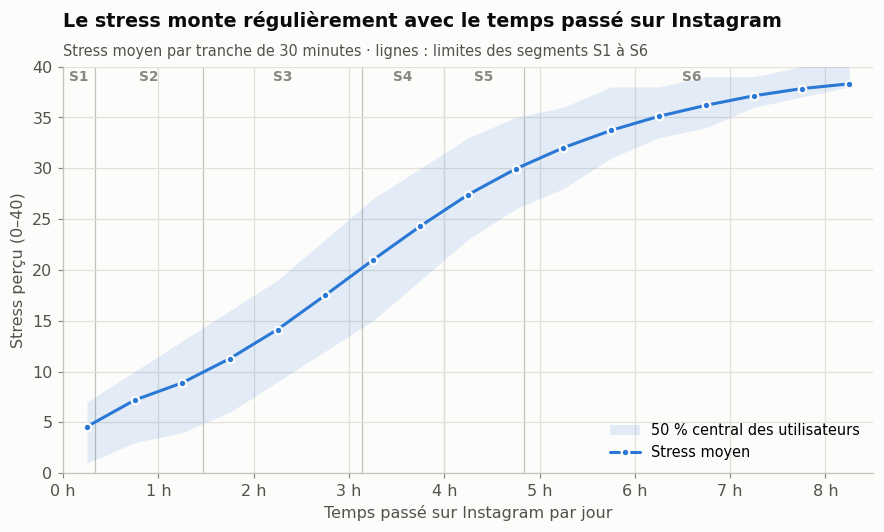

Stress en plus par heure : +5,4 points · part du stress expliquée par le temps passé : 71 %


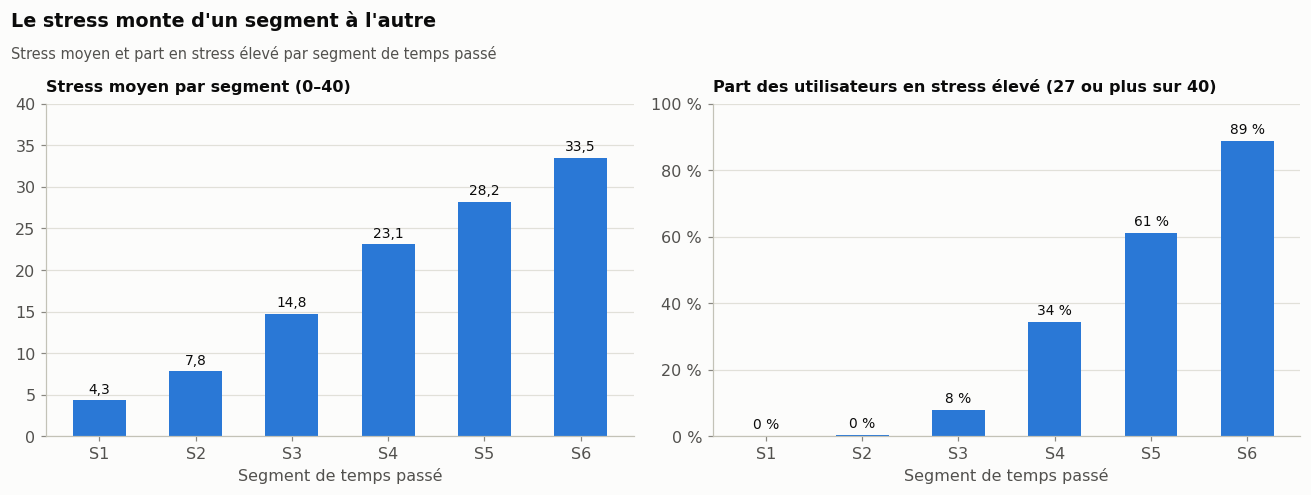

,temps par jour,utilisateurs,temps moyen (min),stress (0–40),bonheur (1–10),stress élevé (%)
segment,,,,,,
S1 Très occasionnel,< 20 min,14 512,"7,0","4,3","8,0","0,0"
S2 Occasionnel,20–88 min,27 884,"56,4","7,8","6,6","0,2"
S3 Modéré,88–188 min,57 823,"138,8","14,8","5,7","7,8"
S4 Soutenu,188–240 min,31 384,"213,2","23,1","5,4","34,5"
S5 Intensif,240–290 min,27 617,"263,7","28,2","5,2","61,2"
S6 Très intensif,> 290 min,40 780,"345,1","33,5","3,9","88,7"


In [11]:
t30 = agreger(df, "tranche_30min", stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"),
              q1=(STRESS, lambda s: s.quantile(0.25)), q3=(STRESS, lambda s: s.quantile(0.75)))
x30 = (t30.index + 15) / 60
pente = np.polyfit(df["heures"], df[STRESS], 1)[0]
r2_stress = part_expliquee(df, STRESS, ["tranche_10min"])
r2_bonheur = part_expliquee(df, BONHEUR, ["tranche_10min"])

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.fill_between(x30, t30["q1"], t30["q3"], color=to_rgba(BLEU, 0.12), linewidth=0, label="50 % central des utilisateurs")
ax.plot(x30, t30["stress"], color=BLEU, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Stress moyen")
for borne in BORNES_SEGMENTS[1:-1]:
    ax.axvline(borne / 60, color=AXIS, linewidth=0.8, zorder=0)
for x, nom in zip([10 / 60, 54 / 60, 138 / 60, 214 / 60, 265 / 60, 6.6], COURTS):
    ax.text(x, 38.6, nom, ha="center", fontsize=9, color=MUTED, fontweight="semibold")
ax.set_xlim(0, 8.5)
ax.set_ylim(0, 40)
ax.xaxis.set_major_formatter(FORMAT_HEURES)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Stress perçu (0–40)")
ax.legend(loc="lower right")
titrer(ax, "Le stress monte régulièrement avec le temps passé sur Instagram",
       "Stress moyen par tranche de 30 minutes · lignes : limites des segments S1 à S6")
plt.show()
print(f"Stress en plus par heure : +{fr(pente)} points · part du stress expliquée par le temps passé : {fr(r2_stress * 100, 0)} %")

segments_temps = agreger(df, "segment", minutes=(TEMPS, "mean"), stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"),
                         part_stress_eleve=("stress_eleve", lambda s: s.mean() * 100))
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4))
barres(ax_g, segments_temps["stress"], COURTS)
ax_g.set_ylim(0, 40)
panneau(ax_g, "Stress moyen par segment (0–40)")
barres(ax_d, segments_temps["part_stress_eleve"], COURTS, decimales=0, suffixe=" %")
ax_d.set_ylim(0, 100)
ax_d.yaxis.set_major_formatter(FORMAT_POURCENT)
panneau(ax_d, "Part des utilisateurs en stress élevé (27 ou plus sur 40)")
for ax in (ax_g, ax_d):
    ax.set_xlabel("Segment de temps passé")
fig.tight_layout()
titrer_figure(fig, "Le stress monte d'un segment à l'autre", "Stress moyen et part en stress élevé par segment de temps passé")
plt.show()

tableau_segments = segments_temps.copy()
tableau_segments.insert(0, "temps par jour", DUREES_SEGMENTS)
afficher(tableau_segments.rename(columns={"n": "utilisateurs", "minutes": "temps moyen (min)", "stress": "stress (0–40)",
                                          "bonheur": "bonheur (1–10)", "part_stress_eleve": "stress élevé (%)"}).rename_axis("segment"))

- Le stress **monte régulièrement** : environ **+5,4 points par heure**, de 4,3 en S1 à 33,5 en S6. Le temps passé explique à lui seul **71 %** des écarts de stress.
- La part d'utilisateurs en **stress élevé** passe de **0 %** en S1 et S2 à **89 %** en S6.

**Sources :** [Riehm et al., 2019 (Johns Hopkins)](https://hub.jhu.edu/2019/09/11/social-media-teen-mental-health/) — au-delà de 3 h par jour, le risque d'anxiété et de dépression des adolescents augmente · [Liu et al., 2022, méta-analyse](https://pmc.ncbi.nlm.nih.gov/articles/PMC9103874/) — chaque heure de plus par jour va avec environ 13 % de risque de dépression en plus.

> **Ce qu'on retient :** **le temps passé est le facteur d'usage le plus lié au stress**, de façon régulière : c'est **l'indicateur numéro un** pour repérer les groupes les plus stressés, et Instagram le mesure déjà pour tous ses utilisateurs.

### 2.2 Le temps passé chaque jour est-il aussi lié au bonheur ?

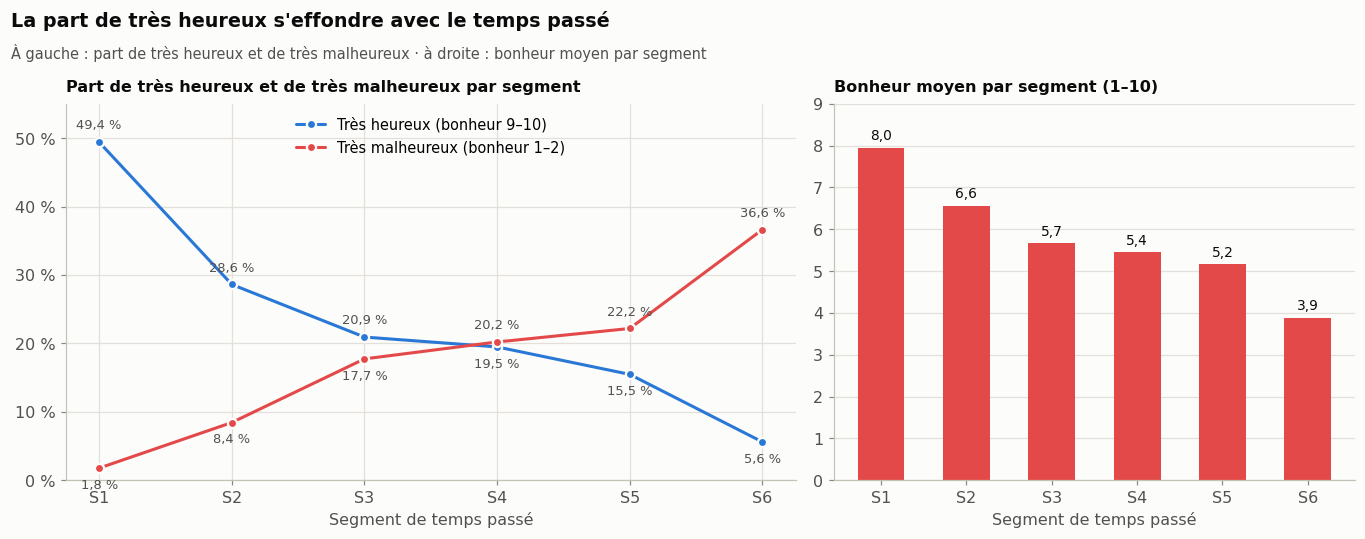

,n,part_tres_heureux,part_tres_malheureux
segment,,,
S1 Très occasionnel,14 512,"49,4","1,8"
S2 Occasionnel,27 884,"28,6","8,4"
S3 Modéré,57 823,"20,9","17,7"
S4 Soutenu,31 384,"19,5","20,2"
S5 Intensif,27 617,"15,5","22,2"
S6 Très intensif,40 780,"5,6","36,6"


,Plus heureux (9–10),Autres,Moins heureux (1–2)
temps médian par jour (min),"128,0","202,0","247,0"
le quart qui y passe le moins : moins de (min),"44,0","118,0","164,0"
sessions par jour,"7,3","11,1","13,6"


In [12]:
bonheur_segments = agreger(df, "segment", part_tres_heureux=("tres_heureux", lambda s: s.mean() * 100),
                           part_tres_malheureux=("tres_malheureux", lambda s: s.mean() * 100))
profils_temps = pd.DataFrame({
    groupe: {"temps médian par jour (min)": df.loc[masque, TEMPS].median(),
             "le quart qui y passe le moins : moins de (min)": df.loc[masque, TEMPS].quantile(0.25),
             "sessions par jour": df.loc[masque, "sessions_per_day"].mean()}
    for groupe, masque in (("Plus heureux (9–10)", df["tres_heureux"]), ("Autres", ~df["tres_heureux"]),
                           ("Moins heureux (1–2)", df["tres_malheureux"]))})

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
positions = np.arange(len(bonheur_segments))
heureux, malheureux = bonheur_segments["part_tres_heureux"].to_numpy(), bonheur_segments["part_tres_malheureux"].to_numpy()
for valeurs, autres, couleur, nom in ((heureux, malheureux, BLEU, "Très heureux (bonheur 9–10)"),
                                      (malheureux, heureux, ROUGE, "Très malheureux (bonheur 1–2)")):
    ax_g.plot(positions, valeurs, color=couleur, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, label=nom)
    for p, v, w in zip(positions, valeurs, autres):
        dessus = v >= w
        ax_g.text(p, v + (1.5 if dessus else -1.5), f"{fr(v)} %", ha="center", va="bottom" if dessus else "top", fontsize=8.5, color=INK2)
ax_g.set_xticks(positions, COURTS)
ax_g.set_ylim(0, 55)
ax_g.yaxis.set_major_formatter(FORMAT_POURCENT)
ax_g.set_xlabel("Segment de temps passé")
ax_g.legend(loc="upper center")
panneau(ax_g, "Part de très heureux et de très malheureux par segment")
barres(ax_d, segments_temps["bonheur"], COURTS, couleur=ROUGE)
ax_d.set_ylim(0, 9)
ax_d.set_xlabel("Segment de temps passé")
panneau(ax_d, "Bonheur moyen par segment (1–10)")
fig.tight_layout()
titrer_figure(fig, "La part de très heureux s'effondre avec le temps passé",
              "À gauche : part de très heureux et de très malheureux · à droite : bonheur moyen par segment")
plt.show()
afficher(bonheur_segments.rename_axis("segment"))
afficher(profils_temps)

- En S1 (moins de 20 min par jour), près de **la moitié** des utilisateurs sont très heureux ; en S6 (plus de 290 min), ils ne sont plus que **6 %**, et plus d'un tiers sont très malheureux.
- Le bonheur moyen **chute surtout aux deux extrêmes** : de 8,0 en S1 à 6,6 en S2, puis il reste entre 5,7 et 5,2 de S3 à S5, avant de tomber à 3,9 en S6. Les **seuils de 20 min et d'environ 4 h 50** (290 min) marquent ces deux chutes : c'est ce que la segmentation apporte de plus qu'un simple classement par temps passé.
- Les plus heureux passent **deux fois moins de temps** sur l'application que les moins heureux (temps médian), et l'ouvrent moins souvent que les autres utilisateurs.

**Note : le temps passé et l'activité disent la même chose.** Les compteurs d'activité (likes, stories, commentaires, messages, publicités, sessions) sont presque des copies du temps passé : plus on reste, plus on agit. Ils n'apportent donc pas d'information en plus (partie 4).

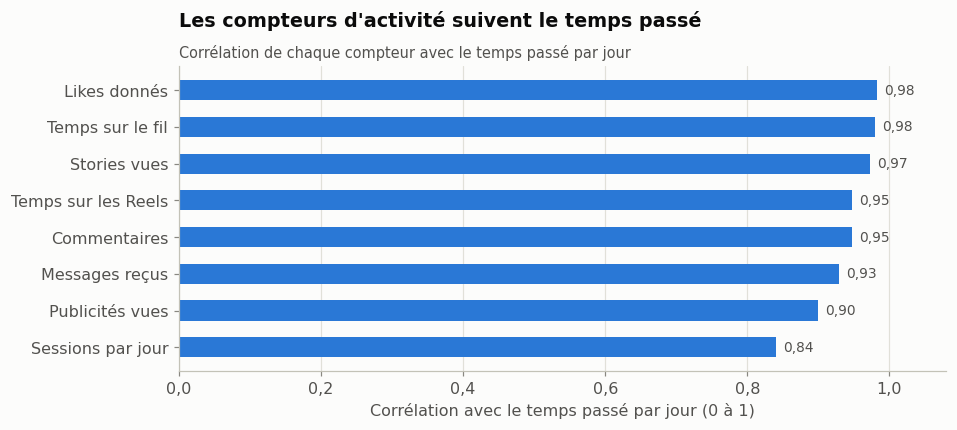

In [13]:
ACTIVITE = {"likes_given_per_day": "Likes donnés", "stories_viewed_per_day": "Stories vues",
            "time_on_feed_per_day": "Temps sur le fil", "time_on_reels_per_day": "Temps sur les Reels",
            "comments_written_per_day": "Commentaires", "dms_received_per_week": "Messages reçus",
            "ads_viewed_per_day": "Publicités vues", "sessions_per_day": "Sessions par jour"}
copies = pd.Series({nom: correlation_rangs(df[c], df[TEMPS]) for c, nom in ACTIVITE.items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(range(len(copies)), copies, height=0.55, color=BLEU)
for p, v in enumerate(copies):
    ax.text(v + 0.01, p, fr(v, 2), va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(copies)), copies.index)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 1)))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Corrélation avec le temps passé par jour (0 à 1)")
titrer(ax, "Les compteurs d'activité suivent le temps passé", "Corrélation de chaque compteur avec le temps passé par jour")
plt.show()

> **Ce qu'on retient :** le temps passé est aussi lié au bonheur : **les plus heureux sont ceux qui utilisent le moins Instagram**, en temps comme en nombre de sessions.

---
## 3. Le rôle de l'âge
*L'âge est la seule variable, en dehors du temps passé, qui change le lien avec le stress.*

### 3.1 D'après l'âge, à usage égal, qui est le plus stressé ?
Pour comparer des utilisateurs à **usage égal**, on regarde le segment **S4 Soutenu** (188 à 240 min par jour, environ 3 h 30 en moyenne dans chaque tranche d'âge).

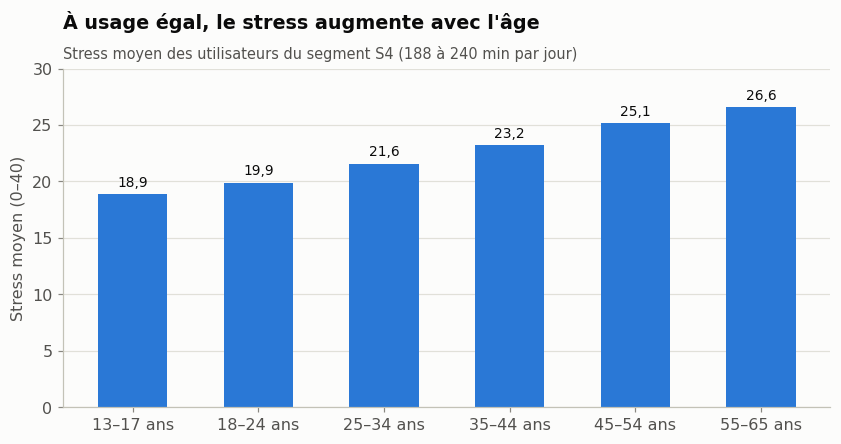

,n,minutes,stress
âge,,,
13–17 ans,2 946,"213,6","18,9"
18–24 ans,4 264,"213,0","19,9"
25–34 ans,6 017,"213,3","21,6"
35–44 ans,5 950,"213,3","23,2"
45–54 ans,5 835,"213,3","25,1"
55–65 ans,6 372,"212,8","26,6"


À temps égal, chaque tranche de 10 ans d'âge en plus va avec +1,2 point de stress.


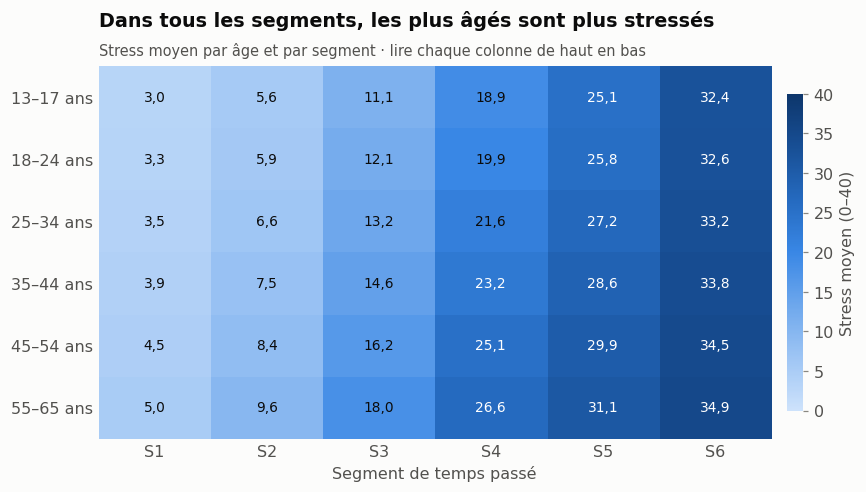

In [14]:
age_s4 = agreger(df[df["segment"] == "S4 Soutenu"], "tranche_age", minutes=(TEMPS, "mean"), stress=(STRESS, "mean"))
ecart = df[STRESS] - df.groupby("tranche_10min")[STRESS].transform("mean")
pente_age = np.polyfit(df["age"], ecart, 1)[0] * 10

fig, ax = plt.subplots(figsize=(9, 4))
barres(ax, age_s4["stress"], age_s4.index)
ax.set_ylim(0, 30)
ax.set_ylabel("Stress moyen (0–40)")
titrer(ax, "À usage égal, le stress augmente avec l'âge", "Stress moyen des utilisateurs du segment S4 (188 à 240 min par jour)")
plt.show()
afficher(age_s4.rename_axis("âge"))
print(f"À temps égal, chaque tranche de 10 ans d'âge en plus va avec +{fr(pente_age, 1)} point de stress.")

grille_age = agreger(df, ["tranche_age", "segment"], stress=(STRESS, "mean"))["stress"].unstack("segment")
grille_age.columns = COURTS
fig, ax = plt.subplots(figsize=(9.5, 4.4))
carte_chaleur(ax, grille_age, 0, 40, "Stress moyen (0–40)", decimales=1)
ax.set_xlabel("Segment de temps passé")
titrer(ax, "Dans tous les segments, les plus âgés sont plus stressés", "Stress moyen par âge et par segment · lire chaque colonne de haut en bas")
plt.show()

- En S4, le stress passe de **18,9** chez les 13–17 ans à **26,6** chez les 55–65 ans.
- Dans tous les segments, les plus âgés sont plus stressés que les plus jeunes ; l'écart est le plus fort dans les segments intermédiaires (jusqu'à 7,7 points en S4).
- Sur l'ensemble des utilisateurs, à temps passé égal, chaque tranche de 10 ans d'âge en plus va avec **+1,2 point** de stress.

> **Ce qu'on retient :** **à usage égal, ce sont les plus âgés qui sont les plus stressés** : l'âge apporte une information en plus du temps passé.

### 3.2 Les plus jeunes passent-ils plus de temps sur Instagram ?

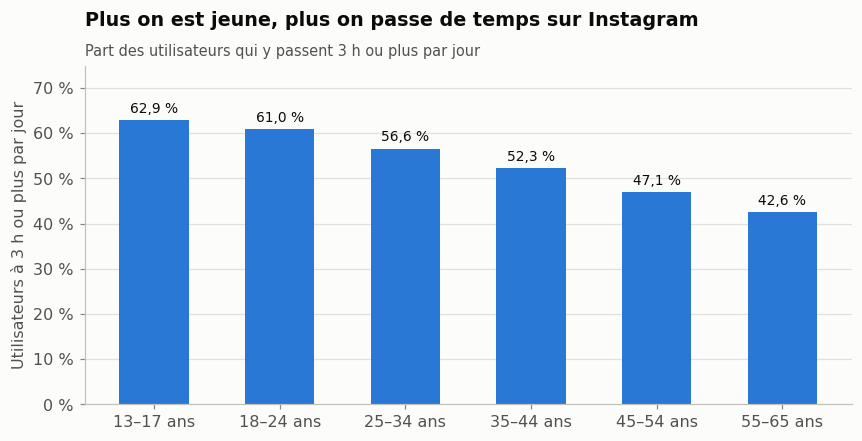

,n,minutes,part_3h_ou_plus
âge,,,
13–17 ans,18 913,"222,7","62,9"
18–24 ans,26 169,"215,1","61,0"
25–34 ans,38 097,"202,4","56,6"
35–44 ans,37 914,"188,1","52,3"
45–54 ans,37 652,"172,9","47,1"
55–65 ans,41 255,"158,8","42,6"


In [15]:
exposition = agreger(df, "tranche_age", minutes=(TEMPS, "mean"), part_3h_ou_plus=(TEMPS, lambda s: (s >= 180).mean() * 100))
fig, ax = plt.subplots(figsize=(9, 4))
barres(ax, exposition["part_3h_ou_plus"], exposition.index, suffixe=" %")
ax.set_ylim(0, 75)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.set_ylabel("Utilisateurs à 3 h ou plus par jour")
titrer(ax, "Plus on est jeune, plus on passe de temps sur Instagram", "Part des utilisateurs qui y passent 3 h ou plus par jour")
plt.show()
afficher(exposition.rename_axis("âge"))

**63 %** des 13–17 ans passent 3 h ou plus par jour sur Instagram, contre **43 %** des 55–65 ans. Le temps moyen baisse de 223 à 159 minutes par jour.

**Pour les équipes produit :** avec un même seuil de temps pour tous, ce sont les plus jeunes que les outils de limitation toucheraient le plus souvent ; ils incluent des **mineurs**, qui demandent des précautions particulières.

**Source :** [question écrite à l'Assemblée nationale citant le rapport « Enfants et écrans » (2024)](https://www.assemblee-nationale.fr/dyn/16/questions/QANR5L16QE18298.pdf) — chez les 16–19 ans, le temps d'écran dépasse les cinq heures ; les experts évoquent la nocivité des réseaux sociaux, « facteur de risque » de dépression ou d'anxiété en cas de « vulnérabilité préexistante ».

> **Ce qu'on retient :** deux effets opposés : les jeunes sont **plus exposés en temps**, les plus âgés sont **plus stressés à temps égal**.

---
## 4. Les habitudes d'utilisation
*Au-delà du temps passé, la façon d'utiliser Instagram est-elle liée au bien-être ?*

Pour chaque habitude, on compare l'écart **brut** et l'écart **à temps passé égal**, c'est-à-dire entre utilisateurs qui passent le même temps sur l'application.

### 4.1 Intensité d'usage : les moins heureux ont-ils un usage plus intensif ?
Moins heureux : bonheur de 1 ou 2 (40 258 utilisateurs) · plus heureux : bonheur de 9 ou 10 (39 905 utilisateurs).

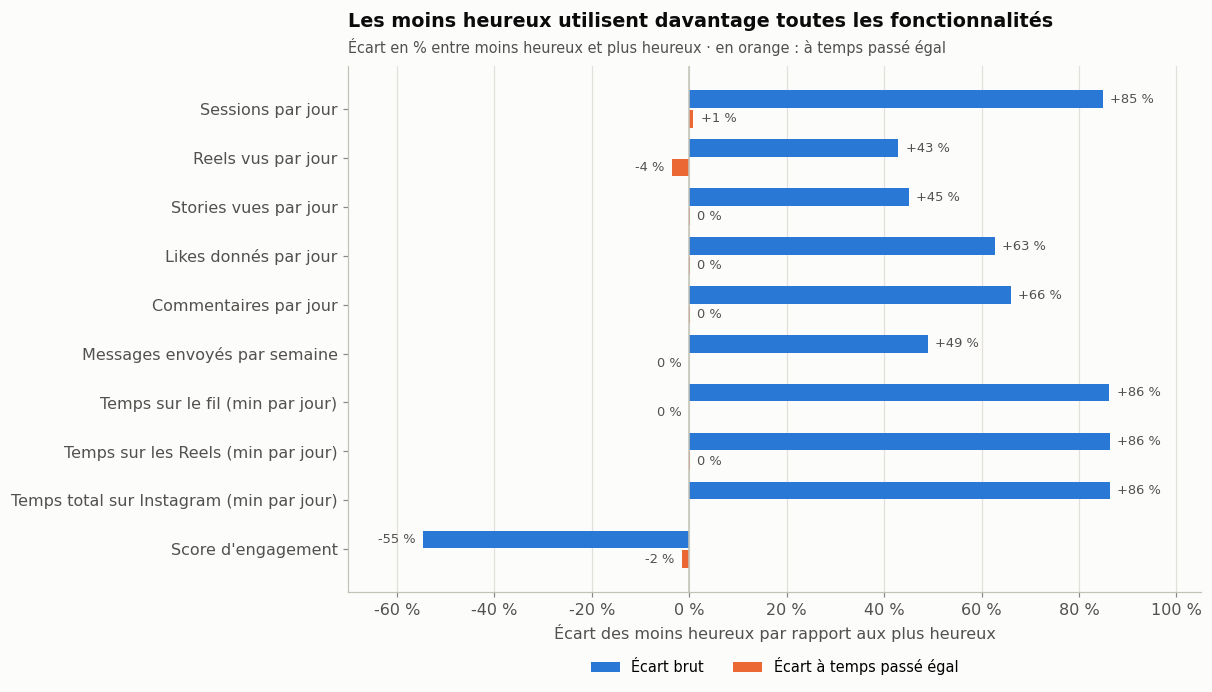

,moins heureux (1–2),plus heureux (9–10),différence (%),différence à temps égal (%)
comportement,,,,
Sessions par jour,"13,6","7,3","84,8","0,9"
Reels vus par jour,"206,9","144,8","42,9","-3,6"
Stories vues par jour,"119,4","82,3","45,1","0,0"
Likes donnés par jour,"148,4","91,2","62,7","0,1"
Commentaires par jour,"43,0","25,9","66,0","0,0"
Messages envoyés par semaine,"34,6","23,3","49,0","-0,1"
Temps sur le fil (min par jour),"123,3","66,2","86,2","0,0"
Temps sur les Reels (min par jour),"74,1","39,8","86,4","0,1"
Temps total sur Instagram (min par jour),"246,8","132,4","86,3",—


Score d'engagement : corrélé à -0,80 avec le temps passé et à 0,94 avec les likes et commentaires par minute.


In [16]:
COMPORTEMENTS = {"sessions_per_day": "Sessions par jour", "reels_watched_per_day": "Reels vus par jour",
                 "stories_viewed_per_day": "Stories vues par jour", "likes_given_per_day": "Likes donnés par jour",
                 "comments_written_per_day": "Commentaires par jour", "dms_sent_per_week": "Messages envoyés par semaine",
                 "time_on_feed_per_day": "Temps sur le fil (min par jour)", "time_on_reels_per_day": "Temps sur les Reels (min par jour)",
                 TEMPS: "Temps total sur Instagram (min par jour)", "user_engagement_score": "Score d'engagement"}
lignes = []
for colonne, nom in COMPORTEMENTS.items():
    moins, plus = df.loc[df["tres_malheureux"], colonne].mean(), df.loc[df["tres_heureux"], colonne].mean()
    if colonne == TEMPS:
        ecart_egal = np.nan
    else:
        egale = a_temps_egal(df, colonne)
        ecart_egal = (egale[df["tres_malheureux"]].mean() / egale[df["tres_heureux"]].mean() - 1) * 100
    lignes.append((nom, moins, plus, (moins / plus - 1) * 100, ecart_egal))
usage = pd.DataFrame(lignes, columns=["comportement", "moins heureux (1–2)", "plus heureux (9–10)",
                                      "différence (%)", "différence à temps égal (%)"]).set_index("comportement")

fig, ax = plt.subplots(figsize=(10, 6.2))
y = np.arange(len(usage))
for k, (colonne, couleur, nom) in enumerate((("différence (%)", BLEU, "Écart brut"),
                                             ("différence à temps égal (%)", ORANGE, "Écart à temps passé égal"))):
    positions = y - 0.2 + 0.4 * k
    valeurs = usage[colonne].fillna(0)
    ax.barh(positions, valeurs, height=0.36, color=couleur, label=nom)
    for p, v, brut in zip(positions, valeurs, usage[colonne]):
        if not pd.isna(brut):
            ax.text(v + (1.5 if v >= 0 else -1.5), p, f"{'+' if v > 0.5 else ''}{fr(v, 0)} %", va="center",
                    ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(y, usage.index)
ax.invert_yaxis()
ax.set_xlim(-70, 105)
ax.xaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Écart des moins heureux par rapport aux plus heureux")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
titrer(ax, "Les moins heureux utilisent davantage toutes les fonctionnalités",
       "Écart en % entre moins heureux et plus heureux · en orange : à temps passé égal")
plt.show()
afficher(usage)
df["interactions_par_minute"] = (df["likes_given_per_day"] + df["comments_written_per_day"]) / df[TEMPS]
print(f"Score d'engagement : corrélé à {fr(correlation_rangs(df['user_engagement_score'], df[TEMPS]), 2)} avec le temps passé "
      f"et à {fr(correlation_rangs(df['user_engagement_score'], df['interactions_par_minute']), 2)} avec les likes et commentaires par minute.")

- Les moins heureux ont **plus de sessions, de Reels, de stories, de likes, de commentaires et de messages**, et passent **86 % de temps en plus** sur l'application.
- Les plus heureux font **moins d'actions**, mais ont un **score d'engagement deux fois plus élevé** : ce score mesure surtout les interactions **par minute** (corrélations ci-dessus), élevées chez ceux qui restent peu de temps.
- À temps passé égal (barres orange), les écarts sont presque nuls (moins de 5 %), y compris pour le score d'engagement.

> **Ce qu'on retient :** les moins heureux ont un usage **beaucoup plus intensif**, sur toutes les fonctionnalités ; les plus heureux agissent moins, avec un **score d'engagement deux fois plus élevé**.

### 4.2 Créer ou consommer : les créateurs de contenu sont-ils moins heureux que les consommateurs ?
Consommateur : 0 à 3 publications par semaine · intermédiaire : 4 à 7 · créateur : 8 et plus · segments : S1 moins de 20 min par jour, S6 plus de 290 min.

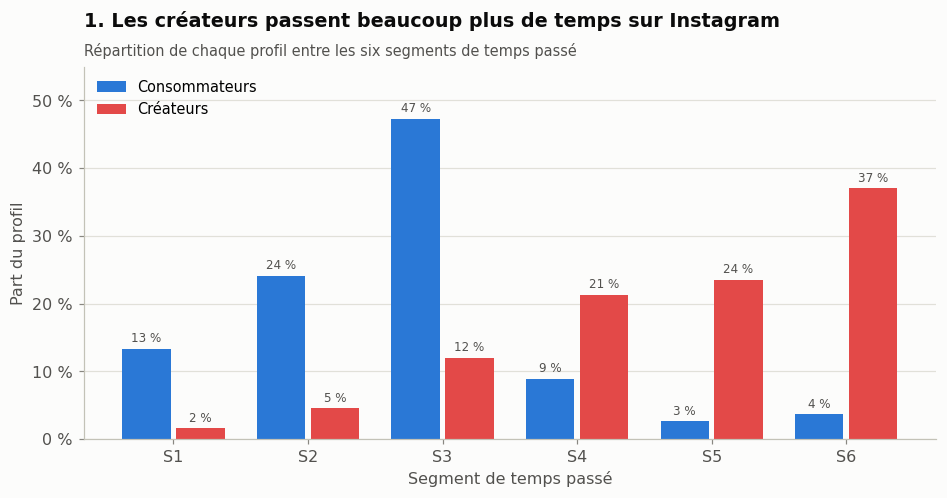

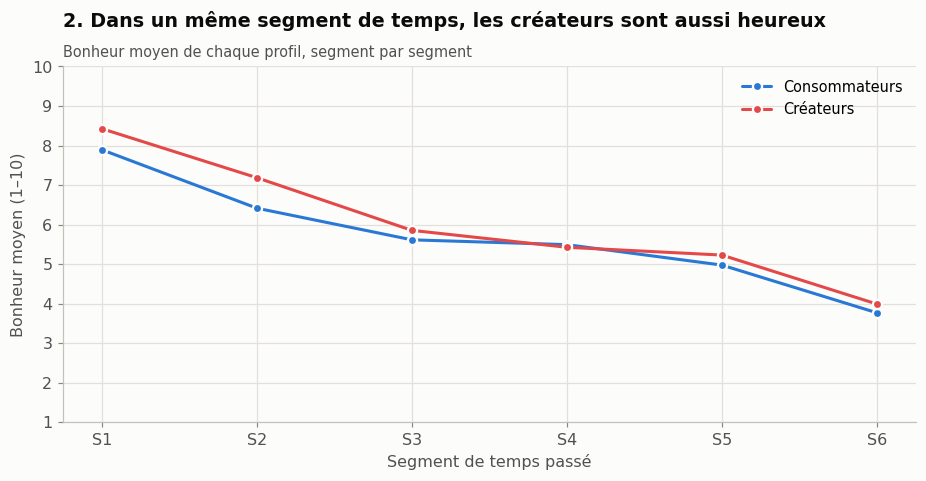

,part des utilisateurs (%),âge moyen,temps par jour (min),bonheur,très heureux (%),très malheureux (%),stress
profil,,,,,,,
Consommateur (0 à 3 publications),"31,6","45,5","117,3","6,0","25,0","15,0","13,9"
Intermédiaire (4 à 7),"37,6","41,1","192,9","5,4","19,4","21,0","20,7"
Créateur (8 et plus),"30,8","29,8","256,8","5,0","15,4","24,4","25,4"


In [17]:
PROFILS_PUBLICATION = ["Consommateur (0 à 3 publications)", "Intermédiaire (4 à 7)", "Créateur (8 et plus)"]
df["profil_publication"] = pd.cut(df["posts_created_per_week"], [-1, 3, 7, 1000], labels=PROFILS_PUBLICATION)
df["bonheur_temps_age_egaux"] = a_temps_egal(df, BONHEUR, "tranche_10min_age")
df["stress_temps_age_egaux"] = a_temps_egal(df, STRESS, "tranche_10min_age")
createurs = agreger(df, "profil_publication", age=("age", "mean"), minutes=(TEMPS, "mean"), bonheur=(BONHEUR, "mean"),
                    tres_heureux=("tres_heureux", lambda s: s.mean() * 100), tres_malheureux=("tres_malheureux", lambda s: s.mean() * 100),
                    stress=(STRESS, "mean"), bonheur_egal=("bonheur_temps_age_egaux", "mean"), stress_egal=("stress_temps_age_egaux", "mean"))
createurs.insert(1, "part", createurs["n"] / len(df) * 100)

NOMS_CC = {"Consommateur (0 à 3 publications)": "Consommateurs", "Créateur (8 et plus)": "Créateurs"}
cc = df.loc[df["profil_publication"].isin(list(NOMS_CC)), ["profil_publication", "segment", STRESS, BONHEUR]]
cc["profil"] = cc["profil_publication"].astype(str).map(NOMS_CC)
repartition = pd.crosstab(cc["profil"], cc["segment"], normalize="index").mul(100)[SEGMENTS]
bonheur_cc = agreger(cc, ["profil", "segment"], bonheur=(BONHEUR, "mean"))["bonheur"].unstack("segment")[SEGMENTS]

fig, ax = plt.subplots(figsize=(10, 4.4))
barres_groupees(ax, repartition.T.set_axis(COURTS), [BLEU, ROUGE], decimales=0, suffixe=" %")
ax.set_ylim(0, 55)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.set_xlabel("Segment de temps passé")
ax.set_ylabel("Part du profil")
ax.legend(loc="upper left")
titrer(ax, "1. Les créateurs passent beaucoup plus de temps sur Instagram",
       "Répartition de chaque profil entre les six segments de temps passé")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
positions = np.arange(len(COURTS))
for profil, couleur in zip(bonheur_cc.index, [BLEU, ROUGE]):
    ax.plot(positions, bonheur_cc.loc[profil], color=couleur, marker="o", markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=1.5, label=profil)
ax.set_xticks(positions, COURTS)
ax.set_ylim(1, 10)
ax.set_xlabel("Segment de temps passé")
ax.set_ylabel("Bonheur moyen (1–10)")
ax.legend(loc="upper right")
titrer(ax, "2. Dans un même segment de temps, les créateurs sont aussi heureux",
       "Bonheur moyen de chaque profil, segment par segment")
plt.show()

afficher(createurs[["part", "age", "minutes", "bonheur", "tres_heureux", "tres_malheureux", "stress"]].rename(columns={
    "part": "part des utilisateurs (%)", "age": "âge moyen", "minutes": "temps par jour (min)",
    "tres_heureux": "très heureux (%)", "tres_malheureux": "très malheureux (%)"}).rename_axis("profil"))

- Les consommateurs comptent **plus de très heureux** que les créateurs (25 % contre 15 %) et **moins de très malheureux** (15 % contre 24 %).
- **Graphique 1 :** les créateurs, **plus jeunes** (30 ans contre 45), se concentrent dans les segments où l'on passe le plus de temps : 37 % d'entre eux en S6, contre 4 % des consommateurs.
- **Graphique 2 :** dans un même segment de temps, les créateurs sont **aussi heureux, voire un peu plus**, car ils sont plus jeunes ; à temps passé et âge égaux, il ne reste aucune différence de bonheur ni de stress.

> **Ce qu'on retient :** les consommateurs sont **plus heureux et moins stressés** que les créateurs ; les créateurs sont **plus jeunes** et passent **deux fois plus de temps** sur l'application.

### 4.3 Privé ou public : l'activité privée est-elle liée à un meilleur bien-être que l'activité publique ?
Activité privée : les messages privés envoyés · activité publique : les likes et les commentaires · part d'activité privée : part des messages dans l'ensemble des interactions, en 5 groupes de taille égale, du plus public (Q1) au plus privé (Q5).

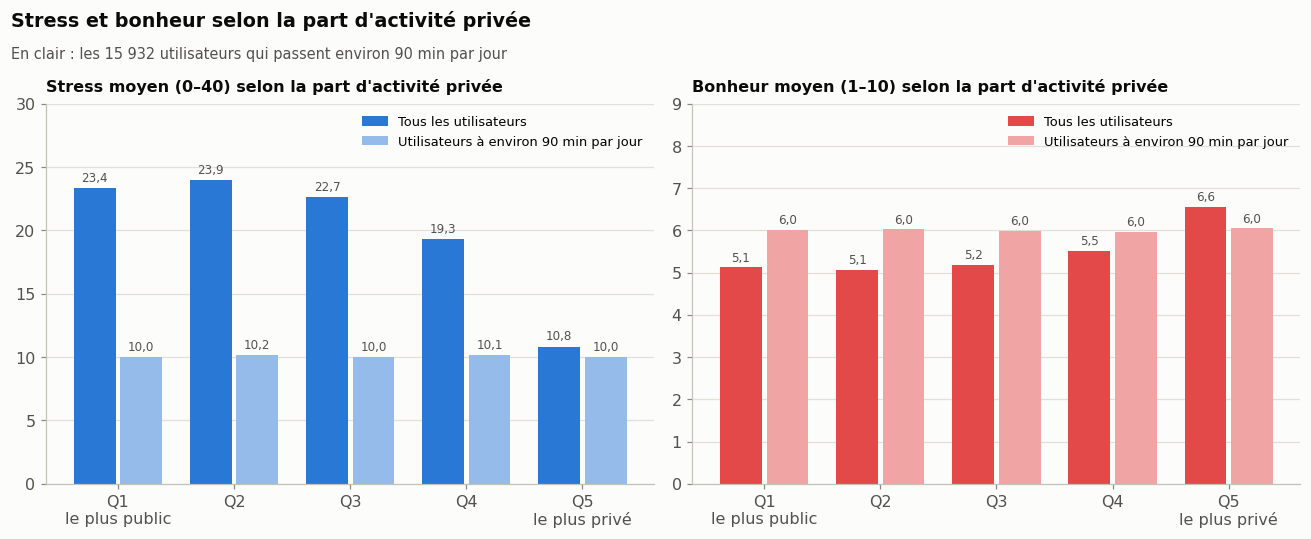

,temps par jour (min),stress,bonheur,likes par jour,commentaires par jour,messages par semaine
groupe,,,,,,
Q1 le plus public,"225,7","23,4","5,1","142,7","41,2","25,8"
Q2,"232,2","23,9","5,1","142,9","41,3","31,2"
Q3,"218,0","22,7","5,2","133,5","38,5","32,8"
Q4,"181,0","19,3","5,5","113,0","32,4","31,5"
Q5 le plus privé,"86,8","10,8","6,6","64,7","18,0","23,1"


,temps par jour (min),stress,bonheur
réglage du compte,,,
Public,"188,9","20,0","5,5"
Amis seulement,"188,4","20,0","5,5"
Privé,"188,9","20,1","5,5"


In [18]:
QUINTILES = ["Q1 le plus public", "Q2", "Q3", "Q4", "Q5 le plus privé"]
COMPTES = {"Public": "Public", "Friends only": "Amis seulement", "Private": "Privé"}
df["part_privee"] = (df["dms_sent_per_week"] / 7) / (df["dms_sent_per_week"] / 7 + df["likes_given_per_day"] + df["comments_written_per_day"]) * 100
df["quintile_prive"] = pd.qcut(df["part_privee"].rank(method="first"), 5, labels=QUINTILES)
vers_90 = df[(df[TEMPS] >= 75) & (df[TEMPS] <= 105)]


def par_groupe(groupe, ordre):
    """Moyennes par groupe : tous les utilisateurs, à temps passé égal, et utilisateurs à environ 90 min par jour."""
    tous, proches = df.groupby(groupe, observed=True), vers_90.groupby(groupe, observed=True)
    return pd.DataFrame({
        "minutes": tous[TEMPS].mean(), "stress": tous[STRESS].mean(), "bonheur": tous[BONHEUR].mean(),
        "stress_temps_egal": tous["stress_temps_egal"].mean(), "bonheur_temps_egal": tous["bonheur_temps_egal"].mean(),
        "stress_vers_90": proches[STRESS].mean(), "bonheur_vers_90": proches[BONHEUR].mean(),
        "likes": tous["likes_given_per_day"].mean(), "commentaires": tous["comments_written_per_day"].mean(),
        "messages": tous["dms_sent_per_week"].mean(),
    }).reindex(ordre)


quintiles = par_groupe("quintile_prive", QUINTILES)
comptes = par_groupe("privacy_setting_level", list(COMPTES)).rename(index=COMPTES)

SERIES_PRIVE = ["Tous les utilisateurs", "Utilisateurs à environ 90 min par jour"]
NOMS_QUINTILES = ["Q1\nle plus public", "Q2", "Q3", "Q4", "Q5\nle plus privé"]
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, variable, couleurs, limite, nom in ((ax_g, "stress", [BLEU, BLEU_CLAIR], 30, "Stress moyen (0–40)"),
                                             (ax_d, "bonheur", [ROUGE, ROUGE_CLAIR], 9, "Bonheur moyen (1–10)")):
    barres_groupees(ax, pd.DataFrame({SERIES_PRIVE[0]: quintiles[variable].to_numpy(),
                                      SERIES_PRIVE[1]: quintiles[f"{variable}_vers_90"].to_numpy()}, index=NOMS_QUINTILES), couleurs)
    ax.set_ylim(0, limite)
    ax.legend(loc="upper right", fontsize=8.5)
    panneau(ax, f"{nom} selon la part d'activité privée")
fig.tight_layout()
titrer_figure(fig, "Stress et bonheur selon la part d'activité privée",
              f"En clair : les {fr(len(vers_90), 0)} utilisateurs qui passent environ 90 min par jour")
plt.show()
afficher(quintiles[["minutes", "stress", "bonheur", "likes", "commentaires", "messages"]].rename(columns={
    "minutes": "temps par jour (min)", "likes": "likes par jour", "commentaires": "commentaires par jour",
    "messages": "messages par semaine"}).rename_axis("groupe"))
afficher(comptes[["minutes", "stress", "bonheur"]].rename(columns={"minutes": "temps par jour (min)"}).rename_axis("réglage du compte"))

- Le stress baisse et le bonheur monte surtout dans les deux groupes **les plus privés** (Q4 et Q5) ; de Q1 à Q3, ils changent peu.
- Les plus privés **likent et commentent deux fois moins**, pour un nombre de messages comparable. Chez les 15 932 utilisateurs qui passent environ 90 min par jour (barres claires), les cinq groupes ont le même stress et le même bonheur.
- Le **réglage du compte** (public, amis seulement, privé) ne change ni le stress, ni le bonheur, ni le temps passé.

> **Ce qu'on retient :** les utilisateurs à l'activité la plus privée sont **deux fois moins stressés et plus heureux**, et passent **2,6 fois moins de temps** sur Instagram.

### 4.4 Réflexe ou immersion : se connecter souvent pour de courtes sessions est-il lié à plus de stress ?
- **Profil réflexe :** beaucoup de connexions courtes, soit plus de sessions par jour que la médiane (9) **et** des sessions plus courtes que la médiane (20,4 min).
- **Profil immersion :** peu de connexions mais longues, soit moins de sessions par jour que la médiane **et** des sessions plus longues que la médiane.

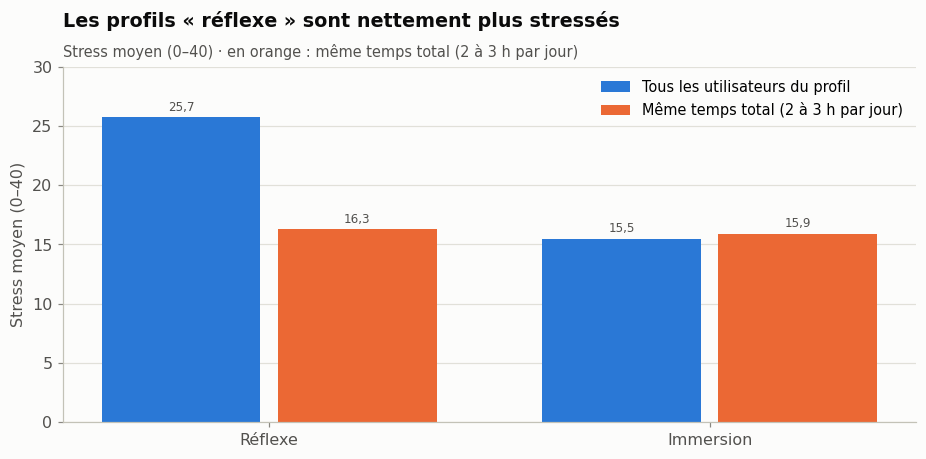

,utilisateurs,sessions par jour,durée d'une session (min),temps total (min par jour),stress (0–40),bonheur (1–10)
profil,,,,,,
Réflexe,59 974,"19,3","13,6","250,2","25,7","4,9"
Immersion,61 543,"4,9","28,8","140,3","15,5","5,8"


Écart de stress : +66 % · à temps total égal : 16,3 contre 15,9


In [19]:
mediane_sessions, mediane_duree = df["sessions_per_day"].median(), df["average_session_length_minutes"].median()
reflexe = (df["sessions_per_day"] > mediane_sessions) & (df["average_session_length_minutes"] < mediane_duree)
immersion = (df["sessions_per_day"] < mediane_sessions) & (df["average_session_length_minutes"] > mediane_duree)
df["profil_connexion"] = np.select([reflexe, immersion], ["Réflexe", "Immersion"], default="Autre")
profils_cx = df[df["profil_connexion"] != "Autre"]
connexion = agreger(profils_cx, "profil_connexion", sessions=("sessions_per_day", "mean"), duree=("average_session_length_minutes", "mean"),
                    minutes=(TEMPS, "mean"), stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean")).reindex(["Réflexe", "Immersion"])
meme_temps = profils_cx[(profils_cx[TEMPS] >= 120) & (profils_cx[TEMPS] < 180)]
connexion_meme = agreger(meme_temps, "profil_connexion", minutes=(TEMPS, "mean"), stress=(STRESS, "mean")).reindex(["Réflexe", "Immersion"])

fig, ax = plt.subplots(figsize=(10, 4.2))
barres_groupees(ax, pd.DataFrame({"Tous les utilisateurs du profil": connexion["stress"].to_numpy(),
                                  "Même temps total (2 à 3 h par jour)": connexion_meme["stress"].to_numpy()},
                                 index=["Réflexe", "Immersion"]), [BLEU, ORANGE])
ax.set_ylim(0, 30)
ax.set_ylabel("Stress moyen (0–40)")
ax.legend(loc="upper right")
titrer(ax, "Les profils « réflexe » sont nettement plus stressés",
       "Stress moyen (0–40) · en orange : même temps total (2 à 3 h par jour)")
plt.show()
afficher(connexion.rename(columns={"n": "utilisateurs", "sessions": "sessions par jour", "duree": "durée d'une session (min)",
                                   "minutes": "temps total (min par jour)", "stress": "stress (0–40)", "bonheur": "bonheur (1–10)"}).rename_axis("profil"))
print(f"Écart de stress : +{fr((connexion.loc['Réflexe', 'stress'] / connexion.loc['Immersion', 'stress'] - 1) * 100, 0)} % · "
      f"à temps total égal : {fr(connexion_meme.loc['Réflexe', 'stress'])} contre {fr(connexion_meme.loc['Immersion', 'stress'])}")

- Les « réflexe » ouvrent Instagram **19 fois par jour** pour des sessions de 14 min ; les « immersion », 5 fois pour 29 min.
- Les « réflexe » sont **66 % plus stressés**, et y passent plus de temps au total (250 min par jour contre 140), car le temps total est égal aux sessions multipliées par leur durée.
- À temps total égal (2 à 3 h par jour), les deux profils ont le même stress : la durée des sessions, seule, n'est pas liée au stress.

**Pour les équipes produit :** un rappel de temps doit compter **le temps cumulé de la journée**, pas seulement la durée d'une session.

> **Ce qu'on retient :** ouvrir Instagram très souvent dans la journée, même pour de courtes sessions, va avec **nettement plus de stress** que se connecter moins souvent mais plus longtemps.

### 4.5 Synthèse des quatre comparaisons

In [20]:
def points(valeur):
    """Écart en points, avec son signe."""
    arrondi = round(valeur, 1)
    return f"{'+' if arrondi > 0 else ''}{fr(valeur, 1)} point{'s' if abs(arrondi) >= 2 else ''}"


def pourcent_signe(valeur):
    return f"{'+' if round(valeur) > 0 else ''}{fr(valeur, 0)} %"


synthese = pd.DataFrame([
    ("4.1 · Moins heureux / plus heureux", "sessions par jour",
     pourcent_signe(usage.loc["Sessions par jour", "différence (%)"]),
     pourcent_signe(usage.loc["Sessions par jour", "différence à temps égal (%)"])),
    ("4.2 · Créateurs / consommateurs", "bonheur (1–10)",
     points(createurs["bonheur"].iloc[2] - createurs["bonheur"].iloc[0]),
     points(createurs["bonheur_egal"].iloc[2] - createurs["bonheur_egal"].iloc[0]) + " (à âge égal aussi)"),
    ("4.3 · Activité la plus privée / la plus publique", "stress (0–40)",
     points(quintiles["stress"].iloc[4] - quintiles["stress"].iloc[0]),
     points(quintiles["stress_temps_egal"].iloc[4] - quintiles["stress_temps_egal"].iloc[0])),
    ("4.4 · Profil réflexe / profil immersion", "stress (0–40)",
     points(connexion.loc["Réflexe", "stress"] - connexion.loc["Immersion", "stress"]),
     points(connexion_meme.loc["Réflexe", "stress"] - connexion_meme.loc["Immersion", "stress"])),
], columns=["comparaison", "indicateur", "écart brut", "écart à temps passé égal"]).set_index("comparaison")
display(synthese)

,indicateur,écart brut,écart à temps passé égal
comparaison,,,
4.1 · Moins heureux / plus heureux,sessions par jour,+85 %,+1 %
4.2 · Créateurs / consommateurs,bonheur (1–10),"-1,0 point","0,0 point (à âge égal aussi)"
4.3 · Activité la plus privée / la plus publique,stress (0–40),"-12,5 points","0,0 point"
4.4 · Profil réflexe / profil immersion,stress (0–40),"+10,2 points","+0,4 point"


> **Ce qu'on retient :** les moins heureux et les plus stressés ont un usage **plus intensif** : plus de temps passé, plus d'actions, plus de publications, une activité plus publique et des connexions plus fréquentes.

---
## 5. Stress et bonheur
*Le stress lié à l'usage s'accompagne-t-il d'une baisse de bonheur ?*

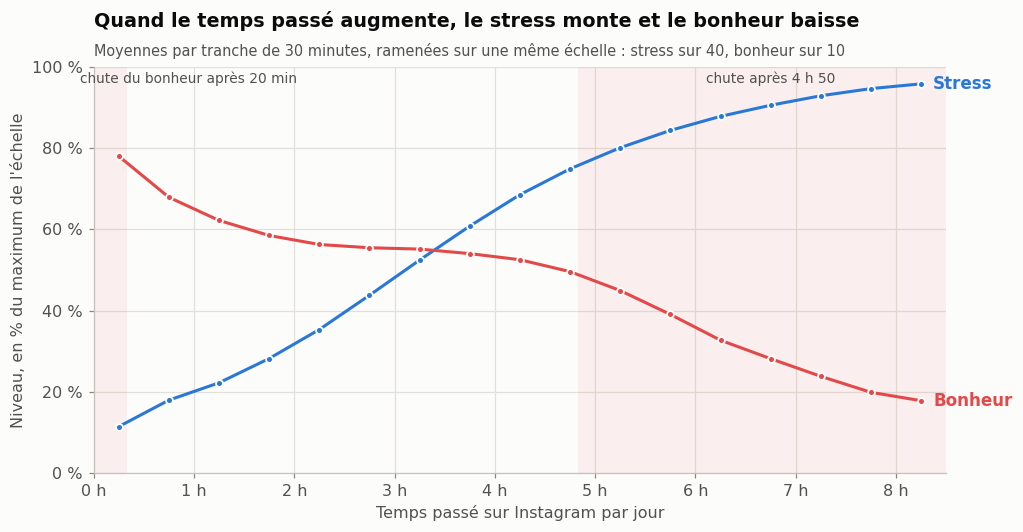

Part des écarts expliquée par le temps passé : stress 71 % · bonheur 16 %


In [21]:
niveaux_30 = pd.DataFrame({"Stress": t30["stress"] / 40 * 100, "Bonheur": t30["bonheur"] / 10 * 100})
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(0, 20 / 60, color=to_rgba(ROUGE, 0.07), linewidth=0)
ax.axvspan(290 / 60, 8.5, color=to_rgba(ROUGE, 0.07), linewidth=0)
ax.text(0.95, 97, "chute du bonheur après 20 min", ha="center", va="center", fontsize=9, color=INK2)
ax.text(6.75, 97, "chute après 4 h 50", ha="center", va="center", fontsize=9, color=INK2)
for nom, couleur in (("Stress", BLEU), ("Bonheur", ROUGE)):
    ax.plot(x30, niveaux_30[nom], color=couleur, marker="o", markersize=4.5, markeredgecolor=SURFACE, markeredgewidth=1.2)
    ax.text(x30[-1] + 0.12, niveaux_30[nom].iloc[-1], nom, color=couleur, fontsize=11, fontweight="semibold", va="center")
ax.set_xlim(0, 8.5)
ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(FORMAT_HEURES)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Niveau, en % du maximum de l'échelle")
titrer(ax, "Quand le temps passé augmente, le stress monte et le bonheur baisse",
       "Moyennes par tranche de 30 minutes, ramenées sur une même échelle : stress sur 40, bonheur sur 10")
plt.show()
print(f"Part des écarts expliquée par le temps passé : stress {fr(r2_stress * 100, 0)} % · bonheur {fr(r2_bonheur * 100, 0)} %")

- Les deux courbes n'ont pas la même forme : le **stress** (en bleu) monte **régulièrement** avec le temps passé, alors que le **bonheur** (en rouge) ne baisse nettement qu'**aux deux extrêmes** (zones rouges, partie 2.2).
- Le temps passé explique **71 %** des écarts de stress, mais seulement **16 %** des écarts de bonheur.

**Pour les équipes produit :** il faut **suivre le stress et le bonheur séparément** : un utilisateur peut être très stressé et très heureux à la fois. Le lien principal d'Instagram est avec **le stress**.

**Source :** [le modèle « dual continua » de Keyes (Frontiers in Psychology, 2022)](https://www.frontiersin.org/articles/10.3389/fpsyg.2022.885278/full) — la santé mentale positive et la détresse sont deux dimensions distinctes.

> **Ce qu'on retient :** le stress lié à l'usage s'accompagne d'une baisse de bonheur, mais **beaucoup plus faible et concentrée aux extrêmes**.

---
## 6. La segmentation
*Deux informations suffisent : le segment de temps passé (S1 à S6) et le groupe d'âge, connus pour tous les utilisateurs.*

### 6.1 Pourquoi des segments par paliers plutôt qu'un regroupement automatique ?
La consigne propose deux voies : **prédire un indicateur de bien-être** à partir de l'usage, ou **regrouper automatiquement** les utilisateurs (*clustering*). Nous avons choisi la première, sous une forme simple : des **segments par paliers** de temps passé, croisés avec l'âge.
- **Un regroupement automatique retrouverait surtout le temps passé** : les compteurs d'activité en sont presque des copies (partie 2.2), et les habitudes d'utilisation n'ajoutent rien à temps égal (partie 4).
- **Ses groupes sont difficiles à expliquer** et peuvent changer d'une exécution à l'autre.
- **Nos segments sont construits pour séparer le stress et le bonheur**, lisibles (« S4 Soutenu, 55–65 ans »), applicables à tous, sans donnée de santé, et calculés en une seule passe sur les 200 000 utilisateurs.

### 6.2 Carte des segments et affectation d'un nouvel utilisateur

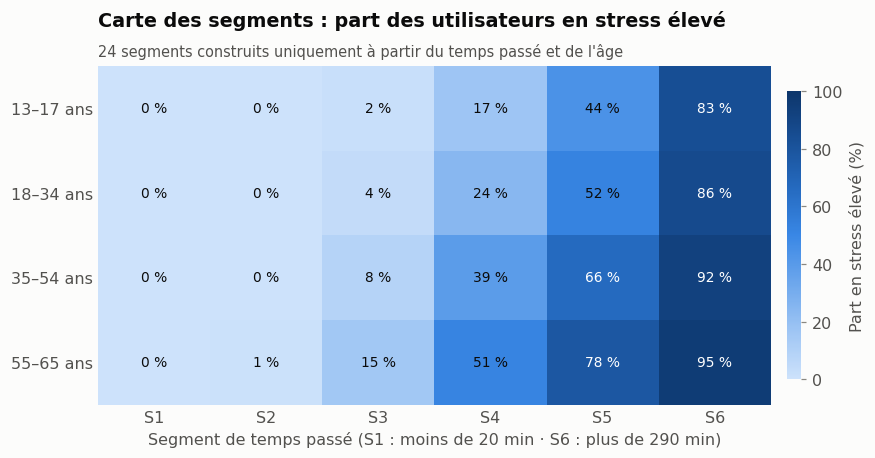

n stress part_stress_eleve
âge       segment                                             
13–17 ans S1 Très occasionnel     549    3,0               0,0
          S2 Occasionnel        1 853    5,6               0,0
          S3 Modéré             5 085   11,1               1,7
          S4 Soutenu            2 946   18,9              16,6
          S5 Intensif           2 841   25,1              43,9
          S6 Très intensif      5 639   32,4              83,2
18–34 ans S1 Très occasionnel   2 768    3,4               0,0
          S2 Occasionnel        7 453    6,3               0,0
          S3 Modéré            18 014   12,8               3,7
          S4 Soutenu           10 281   20,9              24,2
          S5 Intensif           9 420   26,6              51,7
          S6 Très intensif     16 330   32,9              85,9
35–54 ans S1 Très occasionnel   6 054    4,2               0,0
          S2 Occasionnel       11 433    8,0               0,2
          S3 Modéré            22 403   15,4               8,4
          S4 Soutenu           11 785   24,2              38,9
          S5 Intensif          10 359   29,2              66,5
          S6 Très intensif     13 532   34,1              91,8
55–65 ans S1 Très occasionnel   5 141    5,0               0,0
          S2 Occasionnel        7 145    9,6               0,6
          S3 Modéré            12 321   18,0              15,2
          S4 Soutenu            6 372   26,6              51,2
          S5 Intensif           4 997   31,1              78,0
          S6 Très intensif      5 279   34,9              95,3

In [22]:
segments = agreger(df, ["groupe_age", "segment"], stress=(STRESS, "mean"), part_stress_eleve=("stress_eleve", lambda s: s.mean() * 100))
grille = segments["part_stress_eleve"].unstack("segment").reindex(index=GROUPES_AGE, columns=SEGMENTS)
grille_affichee = grille.copy()
grille_affichee.columns = COURTS
fig, ax = plt.subplots(figsize=(9.5, 4))
carte_chaleur(ax, grille_affichee, 0, 100, "Part en stress élevé (%)", suffixe=" %")
ax.set_xlabel("Segment de temps passé (S1 : moins de 20 min · S6 : plus de 290 min)")
titrer(ax, "Carte des segments : part des utilisateurs en stress élevé",
       "24 segments construits uniquement à partir du temps passé et de l'âge")
plt.show()
afficher(segments.rename_axis(["âge", "segment"]))

- Les segments vont de **0 %** à **95 %** d'utilisateurs en stress élevé.
- Dans un même segment de temps, l'âge change fortement le résultat : en S4 (188 à 240 min), **17 %** de stress élevé chez les 13–17 ans contre **51 %** chez les 55–65 ans.

La fonction n'utilise que l'**âge** et le **temps passé par jour**. Les exemples sont des **utilisateurs fictifs**, pas des lignes du fichier.

In [23]:
def assigner_segment(age, minutes_par_jour):
    """Renvoie le segment d'un utilisateur à partir de son âge et de son temps quotidien sur Instagram."""
    if not 13 <= age <= 65:
        raise ValueError("L'âge doit être compris entre 13 et 65 ans (plage couverte par les données).")
    groupe = pd.cut([age], BORNES_GROUPES_AGE, right=False, labels=GROUPES_AGE)[0]
    segment = pd.cut([minutes_par_jour], BORNES_SEGMENTS, right=False, labels=SEGMENTS)[0]
    profil = segments.loc[(groupe, segment)]
    return {"segment": f"{segment} · {groupe}",
            "part en stress élevé dans le segment (%)": float(profil["part_stress_eleve"]),
            "mineur": age < 18}


exemples = [(16, 250), (30, 250), (60, 250), (60, 90)]  # (âge, minutes par jour), utilisateurs fictifs
afficher(pd.DataFrame([{"âge": a, "minutes par jour": m, **assigner_segment(a, m)} for a, m in exemples]))

,âge,minutes par jour,segment,part en stress élevé dans le segment (%),mineur
0,16,250,S5 Intensif · 13–17 ans,"43,9",oui
1,30,250,S5 Intensif · 18–34 ans,"51,7",non
2,60,250,S5 Intensif · 55–65 ans,"78,0",non
3,60,90,S3 Modéré · 55–65 ans,"15,2",non


> **Ce qu'on retient :** une segmentation simple (temps passé × âge), applicable à tous les utilisateurs et sans donnée de santé, qui apporte plus qu'un simple classement par temps passé.

### 6.3 Nos critères d'une bonne segmentation, vérifiés sur les données
Personne ne nous a dit ce qu'est une bonne segmentation : nous fixons nos propres critères, tous **vérifiables sur les données**.

In [24]:
moitie = np.where(df["user_id"] % 2 == 0, "A", "B")
stabilite = (df.assign(moitie=moitie).groupby(["moitie", "groupe_age", "segment"], observed=True)["stress_eleve"]
             .mean().mul(100).unstack("moitie"))
ecarts_age = grille.max() - grille.min()
criteres = pd.DataFrame([
    ("1. Distingue bien le bien-être", "part en stress élevé, du segment le plus bas au plus haut",
     f"de {fr(grille.min().min(), 0)} % à {fr(grille.max().max(), 0)} %"),
    ("2. Apporte plus que le temps seul", "plus grand écart entre groupes d'âge dans un même segment de temps",
     f"{fr(ecarts_age.max(), 1)} points ({ecarts_age.idxmax()})"),
    ("3. S'applique à tout utilisateur", "valeurs manquantes dans l'âge et le temps passé", str(int(df[["age", TEMPS]].isna().sum().sum()))),
    ("4. Est stable", "plus grand écart entre deux moitiés du fichier", f"{fr((stabilite['A'] - stabilite['B']).abs().max(), 1)} point{'s' if round((stabilite['A'] - stabilite['B']).abs().max(), 1) >= 2 else ''}"),
    ("5. N'isole personne", "plus petit segment", f"{fr(df.groupby(['groupe_age', 'segment'], observed=True).size().min(), 0)} utilisateurs"),
    ("6. Aucune donnée de santé", "variables utilisées", "âge et temps passé par jour"),
], columns=["critère", "mesure", "résultat"]).set_index("critère")
display(criteres)

,mesure,résultat
critère,,
1. Distingue bien le bien-être,"part en stress élevé, du segment le plus bas a...",de 0 % à 95 %
2. Apporte plus que le temps seul,plus grand écart entre groupes d'âge dans un m...,"34,6 points (S4 Soutenu)"
3. S'applique à tout utilisateur,valeurs manquantes dans l'âge et le temps passé,0
4. Est stable,plus grand écart entre deux moitiés du fichier,"1,7 point"
5. N'isole personne,plus petit segment,549 utilisateurs
6. Aucune donnée de santé,variables utilisées,âge et temps passé par jour


> **Ce qu'on retient :** les six critères sont atteints, tous vérifiés sur les données.

### 6.4 Quatre profils de bien-être selon le segment
On croise le stress (élevé à partir de 27 sur 40) et le bonheur (élevé à partir de 7 sur 10).

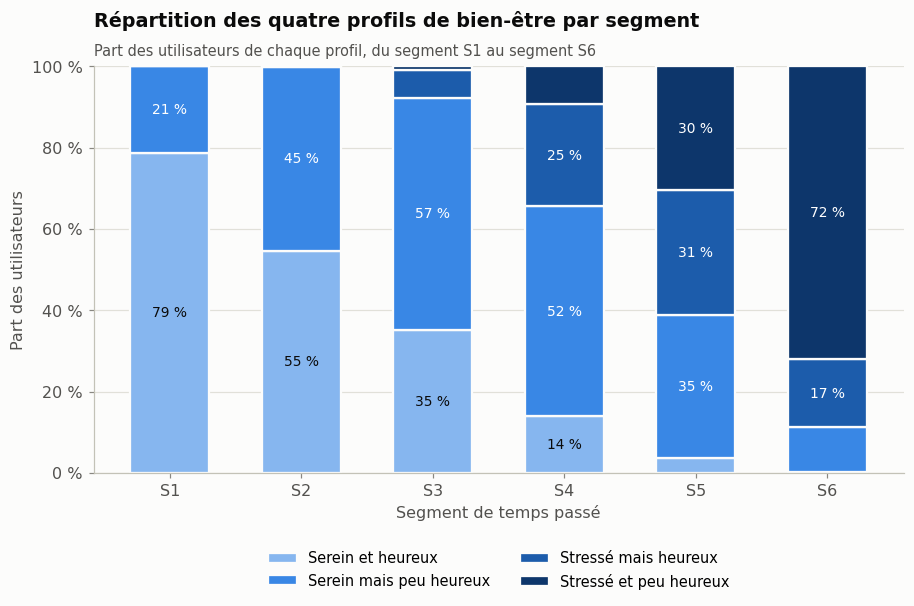

profil,Serein et heureux,Serein mais peu heureux,Stressé mais heureux,Stressé et peu heureux
segment,,,,
S1 Très occasionnel,"78,7","21,3","0,0","0,0"
S2 Occasionnel,"54,6","45,1","0,2","0,0"
S3 Modéré,"35,2","57,0","6,9","0,9"
S4 Soutenu,"14,0","51,6","25,1","9,4"
S5 Intensif,"3,7","35,1","30,8","30,4"
S6 Très intensif,"0,3","11,0","16,7","72,1"


In [25]:
PROFILS = ["Serein et heureux", "Serein mais peu heureux", "Stressé mais heureux", "Stressé et peu heureux"]
profil = np.select([~df["stress_eleve"] & (df[BONHEUR] >= 7), ~df["stress_eleve"] & (df[BONHEUR] < 7),
                    df["stress_eleve"] & (df[BONHEUR] >= 7)], PROFILS[:3], default=PROFILS[3])
parts = pd.crosstab(df["segment"], profil, normalize="index").mul(100)[PROFILS]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
positions = np.arange(len(parts))
base = np.zeros(len(parts))
for couleur, nom in zip(RAMPE_4, PROFILS):
    ax.bar(positions, parts[nom], bottom=base, width=0.6, color=couleur, edgecolor=SURFACE, linewidth=1.5, label=nom)
    for p, b, v in zip(positions, base, parts[nom]):
        if v >= 12:
            ax.text(p, b + v / 2, f"{fr(v, 0)} %", ha="center", va="center", fontsize=9, color=INK if couleur == RAMPE_4[0] else "white")
    base += parts[nom].to_numpy()
ax.set_xticks(positions, COURTS)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Segment de temps passé")
ax.set_ylabel("Part des utilisateurs")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
titrer(ax, "Répartition des quatre profils de bien-être par segment", "Part des utilisateurs de chaque profil, du segment S1 au segment S6")
plt.show()
afficher(parts.rename_axis(index="segment", columns="profil"))

- En S1, près de **quatre utilisateurs sur cinq** sont sereins et heureux.
- En S6, près des **trois quarts** sont stressés et peu heureux.
- Entre les deux, on passe d'abord par « serein mais peu heureux », puis par « stressé mais heureux ».

**Pour les équipes produit :** ces profils décrivent **le parcours du bien-être selon la dose d'usage**. Ils restent une lecture des résultats agrégés : **on ne les attribue pas à un utilisateur**, puisqu'ils reposent sur des données de santé du panel.

> **Ce qu'on retient :** plus la dose d'usage augmente, plus les utilisateurs glissent d'un profil serein et heureux vers un profil stressé et peu heureux.

---
## 7. Protection des données
*Notre position pour les utilisateurs de l'Union européenne et du Royaume-Uni, y compris les moins de 18 ans.*

### 7.1 Sur quelles variables les segments peuvent-ils reposer pour du ciblage ?
**Uniquement le temps passé par jour et l'âge.**
- Ce sont des données qu'Instagram détient **pour tous ses utilisateurs**, et ce ne sont **pas des données de santé**.
- **Les variables de santé et de bien-être sont exclues** (stress, bonheur, sommeil, IMC, tension, tabac, alcool, alimentation, sport) : ce sont des données sensibles au sens de l'article 9 du RGPD ([CNIL](https://www.cnil.fr/fr/definition/donnee-sensible)), données seulement pour l'étude bien-être.
- **Les autres variables de profil sont exclues aussi** (genre, revenu, emploi, couple, enfants, pays) : elles n'apportent rien, et le RGPD demande de ne traiter que les données nécessaires.

### 7.2 Placer un utilisateur dans un segment peut-il révéler quelque chose sur sa santé ?

In [26]:
groupe_max, segment_max = segments["part_stress_eleve"].idxmax()
revelateurs = segments[segments["part_stress_eleve"] >= 80]
print(f"Segment le plus révélateur : {segment_max} · {groupe_max}, avec {fr(segments['part_stress_eleve'].max(), 0)} % de ses membres en stress élevé")
print(f"{len(revelateurs)} segments sur {len(segments)} comptent au moins 80 % d'utilisateurs en stress élevé "
      f"({fr(revelateurs['n'].sum() / len(df) * 100, 0)} % des utilisateurs).")

Segment le plus révélateur : S6 Très intensif · 55–65 ans, avec 95 % de ses membres en stress élevé
4 segments sur 24 comptent au moins 80 % d'utilisateurs en stress élevé (20 % des utilisateurs).


**Oui.** Même construits sans donnée de santé, certains segments laissent deviner un état de stress avec une forte probabilité. Une donnée qui révèle indirectement un état de santé doit être traitée comme une donnée de santé. D'où trois conditions :
- **nommer les segments par l'usage** (« S6 Très intensif, 55–65 ans »), jamais par le stress attendu ;
- **ne stocker aucun score de stress** par utilisateur ;
- **réserver les segments aux outils de protection** (rappels de temps, mode sommeil), sans publicité.

### 7.3 Les mineurs
- **Royaume-Uni :** le code de conception adapté à l'âge de l'ICO demande que **le profilage des enfants soit désactivé par défaut**, sauf raison impérieuse dans leur intérêt ([résumé par RPC](https://www.rpclegal.com/snapshots/data-protection/ico-age-appropriate-design-code-for-information-society-services/)).
- **Union européenne :** le DSA (article 28) **interdit les publicités fondées sur le profilage** d'un utilisateur dont la plateforme sait qu'il est mineur ([EUR-Lex](https://eur-lex.europa.eu/eli/reg/2022/2065/oj)).

### 7.4 Les mesures que nous appliquons et recommandons
- **Seuil de 100 utilisateurs :** aucune ligne individuelle ni aucun groupe de moins de 100 personnes n'est affiché (vérification ci-dessous).
- **Données brutes jamais publiées :** le dossier `data/` est exclu du dépôt du projet par le fichier `.gitignore` ; seule la copie qui sert à l'application en ligne se trouve dans un dépôt privé.
- **Des parties dédiées aux limites et à la protection des données**, dans le notebook, l'application et le README.
- **Interdiction écrite** d'utiliser les segments pour la publicité ou de les transmettre aux annonceurs.
- **Informer les utilisateurs** du classement en segments, dans la politique de confidentialité.
- **Inscrire le traitement au registre des traitements**, avec sa finalité, les données utilisées et la durée de conservation.

In [27]:
afficher(pd.Series({
    "segments de temps (S1 à S6)": df.groupby("segment", observed=True).size().min(),
    "segments âge × temps": df.groupby(["groupe_age", "segment"], observed=True).size().min(),
    "âge × temps (tranches fines)": df.groupby(["tranche_age", "segment"], observed=True).size().min(),
}, name="plus petit groupe (utilisateurs)").to_frame(), 0)

,plus petit groupe (utilisateurs)
segments de temps (S1 à S6),14 512
segments âge × temps,549
âge × temps (tranches fines),549


---
## 8. Limites
*Ce que nos données ne permettent pas d'affirmer.*

### 8.1 Pas de cause à effet
Tous nos liens sont des **corrélations**. On ne peut pas dire qu'Instagram *cause* le stress : les personnes stressées pourraient aussi passer plus de temps sur l'application. Seules des expériences, où l'on fait varier le temps passé, peuvent tester une cause.

### 8.2 Un panel de volontaires
Le stress et le bonheur ne sont mesurés que chez les **volontaires** de l'étude bien-être. Ils ne ressemblent pas forcément à l'ensemble des utilisateurs.

### 8.3 Une réplique synthétique
- **Le lien entre temps passé et stress est très fort** : 71 % des écarts expliqués, contre 0,4 % au maximum dans les études réelles ([Orben & Przybylski, 2019](https://www.oii.ox.ac.uk/technology-use-explains-at-most-0-4-of-adolescent-wellbeing/)).
- **Des effets connus sont absents** : le sommeil, les pas et le sport n'ont aucun lien ici, alors que nos sources associent le sommeil et l'activité physique au bien-être (partie 1).
- **Les deux versions du fichier (« usage » et « users ») sont presque identiques**, et le nettoyage de l'une n'est pas documenté (partie 0).
- **26 % des lignes ont au moins une incohérence métier** : elles sont signalées, et les résultats ne changent pas sans elles (partie 0).
- **Un lien caché, très probablement artificiel, entre stress et bonheur** :

Corrélation stress ↔ bonheur sur tous les utilisateurs : 0,00
Corrélation stress ↔ bonheur à temps passé égal : 0,60


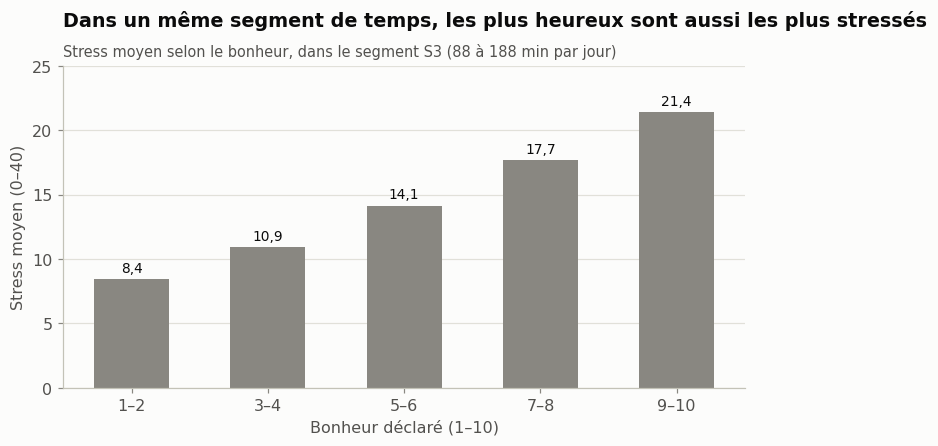

In [28]:
residu = lambda c: df[c] - df.groupby("tranche_10min")[c].transform("mean")  # noqa: E731
print(f"Corrélation stress ↔ bonheur sur tous les utilisateurs : {fr(df[STRESS].corr(df[BONHEUR]), 2)}")
print(f"Corrélation stress ↔ bonheur à temps passé égal : {fr(np.corrcoef(residu(STRESS), residu(BONHEUR))[0, 1], 2)}")
niveau_bonheur = pd.cut(df[BONHEUR], [0, 2, 4, 6, 8, 10], labels=["1–2", "3–4", "5–6", "7–8", "9–10"])
lien_cache = agreger(df[df["segment"] == "S3 Modéré"].assign(niveau_bonheur=niveau_bonheur), "niveau_bonheur", stress_moyen=(STRESS, "mean"))
fig, ax = plt.subplots(figsize=(8, 3.8))
barres(ax, lien_cache["stress_moyen"], lien_cache.index, couleur=MUTED)
ax.set_ylim(0, 25)
ax.set_xlabel("Bonheur déclaré (1–10)")
ax.set_ylabel("Stress moyen (0–40)")
titrer(ax, "Dans un même segment de temps, les plus heureux sont aussi les plus stressés",
       "Stress moyen selon le bonheur, dans le segment S3 (88 à 188 min par jour)")
plt.show()

- Sur l'ensemble des utilisateurs, stress et bonheur **ne sont pas liés**. Mais **à temps passé égal**, ils sont **fortement liés, dans le même sens** : les deux effets se compensent, car le temps passé fait monter le stress et baisser le bonheur.
- **C'est très probablement un effet de la génération des données** : dans la réalité, on s'attend plutôt à ce que les personnes stressées soient moins heureuses. Ce lien ne sert pas à la segmentation.

### 8.4 Autres points de prudence
- **Le seuil de stress élevé (27)** est une convention de lecture de l'échelle PSS-10, pas un seuil de diagnostic.
- **Les colonnes « story privée » et « partages » n'existent pas** : l'activité privée n'est mesurée que par les messages (partie 4.3).

> **Ce qu'on retient :** nos résultats décrivent **des tendances fortes dans une réplique synthétique**. Ils indiquent où regarder, mais doivent être **confirmés sur de vraies données**, et ne permettent jamais de conclure à une cause.

---
## 9. Conclusion et recommandations
*Ce qu'il faut retenir, et ce que les équipes produit peuvent en faire.*

### Le lien entre l'usage d'Instagram et le bien-être
- **Le temps passé chaque jour est le facteur central.** Il explique **71 %** des écarts de stress (environ +5,4 points par heure) et **16 %** des écarts de bonheur, qui chute surtout aux deux extrêmes.
- **L'âge change ce lien.** Les plus jeunes passent plus de temps sur Instagram, mais à temps égal, les plus âgés sont plus stressés (+1,2 point par tranche de 10 ans).
- **Les habitudes d'utilisation vont dans le même sens** : les moins heureux et les plus stressés ont un usage plus intensif (plus d'actions, plus de publications, une activité plus publique, des connexions plus fréquentes) et passent plus de temps sur l'application.
- **Le sommeil, l'activité physique et le pays ne sont pas liés** à l'usage dans notre panel.
- **Stress et bonheur sont deux indicateurs distincts**, à suivre séparément.

### Une segmentation utilisable par les équipes produit
**Six segments de temps passé (S1 à S6) croisés avec quatre groupes d'âge** : deux informations connues pour tous les utilisateurs, sans donnée de santé. La carte des segments désigne directement les groupes à accompagner en priorité, et la fonction `assigner_segment` (partie 6.2) place n'importe quel nouvel utilisateur.

### Recommandations
1. **Un rappel de temps quotidien cumulé, avec un seuil selon l'âge.** Dès le segment S3 (88 à 188 min par jour), 15 % des 55–65 ans sont en stress élevé, contre 2 % des 13–17 ans, qui ne dépassent 15 % qu'en S4. Nous recommandons un rappel **à l'entrée de S3 (environ 1 h 30 par jour) pour les 55–65 ans** et **à l'entrée de S4 (environ 3 h) pour les autres**, **activé par défaut pour les mineurs**. Le rappel compte le temps **de toute la journée**, pas celui d'une seule session (partie 4.4).
2. **Faire du temps quotidien passé l'indicateur de suivi numéro un**, par segment, dans les tableaux de bord produit, plutôt que les compteurs d'activité ou le score d'engagement ; dans les études bien-être, **suivre le stress et le bonheur séparément**.
3. **Réserver les segments aux outils de protection** (rappels, mode sommeil) : jamais de publicité, des segments nommés par l'usage et non par le stress, et une analyse d'impact sur la protection des données avant tout déploiement.

> **En une phrase :** plus on passe de temps sur Instagram, plus on est stressé, et ce lien est plus fort chez les plus âgés ; une segmentation simple par temps passé et âge permet aux équipes produit de cibler leurs outils de protection, sans utiliser de données de santé.

---
## Sources
*Les références citées dans l'analyse.*

**Définitions**
- OMS : [constitution de l'Organisation mondiale de la santé](https://www.who.int/fr/about/governance/constitution)
- Santé publique France : [« On a toutes et tous une santé mentale » (sante.fr)](https://www.sante.fr/toutes-et-tous-une-sante-mentale)
- World Happiness Report : [questions fréquentes, échelle de Cantril](https://www.worldhappiness.report/faq/)
- Échelle PSS-10 : [guide de cotation (NovoPsych)](https://novopsych.com.au/wp-content/uploads/2022/02/pss-10-report-PDF.pdf)

**Temps passé, âge et bien-être**
- Riehm et al., 2019, *JAMA Psychiatry* : [présentation par Johns Hopkins](https://hub.jhu.edu/2019/09/11/social-media-teen-mental-health/)
- Liu et al., 2022, méta-analyse dose–effet : [texte intégral (PMC)](https://pmc.ncbi.nlm.nih.gov/articles/PMC9103874/)
- Orben & Przybylski, 2019, *Nature Human Behaviour* : [Oxford Internet Institute](https://www.oii.ox.ac.uk/technology-use-explains-at-most-0-4-of-adolescent-wellbeing/)
- Assemblée nationale, question écrite citant le rapport « Enfants et écrans » (2024) : [PDF](https://www.assemblee-nationale.fr/dyn/16/questions/QANR5L16QE18298.pdf)
- Modèle de Keyes : [Frontiers in Psychology, 2022](https://www.frontiersin.org/articles/10.3389/fpsyg.2022.885278/full)

**Mode de vie**
- info.gouv.fr, 2025 : [le sommeil et la santé mentale](https://www.info.gouv.fr/actualite/sante-mentale-pourquoi-le-sommeil-joue-un-role-cle)
- Ameli : [activité physique et bien-être](https://www.ameli.fr/assure/sante/themes/activite-physique-sante/sport-et-activite-physique-un-atout-pour-le-bien-etre)

**Protection des données**
- [CNIL, données sensibles](https://www.cnil.fr/fr/definition/donnee-sensible) · [DSA (EUR-Lex)](https://eur-lex.europa.eu/eli/reg/2022/2065/oj) · [code de l'ICO (résumé par RPC)](https://www.rpclegal.com/snapshots/data-protection/ico-age-appropriate-design-code-for-information-society-services/)